# FINAL NOTEBOOK 02 — CHIRPS v2 vs v3 RNL: Spatial and Temporal Diagnostics
**PH3043 · Six Sri Lankan stations · 1981–2000**

**Research questions.** H1: v3 has lower matched daily RMSE than v2. H2: daily association changes when measurements are accumulated into CHIRPS calendar pentads, fixed weeks and complete months. H3 (exploratory): 5/10 km spatial averaging improves gauge agreement. H4 (exploratory): within-pentad rainfall allocation explains some daily error.

This notebook **does not fit or select a correction model**. Notebook 01 established the compulsory baseline. Notebook 03 will fit daily corrections; Notebook 04 will fit pentad/monthly corrections.

**Validation rules.** Compare raw products on *identical station–date pairs*. Report 1991–1994 as our development validation window; optional 1981–2000 is descriptive only; do **not** select a model/buffer based on 1995–2000. Past exploratory analysis already inspected that period, so it is not fully untouched.

**No new GEE exports required.** Optional spatial-buffer processing runs only if annual buffer CSVs actually exist locally.


## 0. Setup and reusable directory discovery
Run once. The root search works whether Jupyter starts in `notebooks/Final_Notebooks/`, `notebooks/`, or the project root. Point `DATA_PATH` to your existing `.csv` if autodetection fails. Outputs go in `results/Final_02_CHIRPS_Scales/`; no existing tables/figures are overwritten.

In [1]:
from pathlib import Path
from datetime import datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

STATIONS = ['Badulla','Colombo','Galle','Kandy','Nuwaraeliya','Puttalam']
PRODUCTS = {'CHIRPS v2':'CHIRPS_mm','CHIRPS v3 RNL':'CHIRPS_V3_mm'}
VALID = ('1991-01-01','1994-12-31')
TRAIN = ('1981-01-01','1990-12-31')
TEST = ('1995-01-01','2000-12-31')
FULL = ('1981-01-01','2000-12-31')
DATA_FILENAME = 'Ground_CHIRPS_V2_V3_Paired_1981_2000.csv'
DATA_PATH = None  # set to an absolute path only if needed

def locate_project_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p/'data').is_dir() and (p/'notebooks').is_dir(): return p
    return here
PROJECT_ROOT = locate_project_root()
def find_paired_data():
    if DATA_PATH is not None: return Path(DATA_PATH)
    folders=[PROJECT_ROOT/'data'/'processed',PROJECT_ROOT/'data',PROJECT_ROOT,Path.cwd(),Path('/mnt/data')]
    for folder in folders:
        for name in [DATA_FILENAME,DATA_FILENAME.replace('.csv','.xls')]:
            f=folder/name
            if f.exists():return f
    raise FileNotFoundError('Set DATA_PATH to your existing paired CSV; no new extraction is needed.')
SOURCE=find_paired_data()
BASE=PROJECT_ROOT/'results'/'Final_02_CHIRPS_Scales'
BASE.mkdir(parents=True,exist_ok=True)
RUN=next(BASE/f'run_{k:03d}' for k in range(1,10000) if not (BASE/f'run_{k:03d}').exists())
FIGDIR=RUN/'figures'; TABDIR=RUN/'tables'; FIGDIR.mkdir(parents=True); TABDIR.mkdir()
plt.rcParams.update({'font.size':10,'figure.dpi':115,'axes.spines.top':False,'axes.spines.right':False})
print('Project root:',PROJECT_ROOT,'\nInput:',SOURCE,'\nOutput:',RUN)

Project root: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach 
Input: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_V2_V3_Paired_1981_2000.csv 
Output: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_02_CHIRPS_Scales\run_001


## 1. Data provenance and matched-pair quality control
**Scientific principle:** a gauge is a point observation; CHIRPS is a grid-cell estimate. Do not confuse the 5/10 km spatial radius with the five-day temporal pentad.

- v2 GEE ID: `UCSB-CHG/CHIRPS/DAILY`.
- v3 RNL GEE ID: `UCSB-CHC/CHIRPS/V3/DAILY_RNL`.
- Band: `precipitation`, mm/day; extraction scale 5,566 m.
- Point reducer `ee.Reducer.first()`; buffer reducer `ee.Reducer.mean()` over radii 5,000 and 10,000 m.
- Annual export controls: `VERSION` (`v2` or `v3rnl`) and `YEAR` (1981–2000); six coordinate points.
- CHIRPS v3 daily reanalysis uses ERA5-derived proportions for disaggregating pentad totals; temporal diagnostics can **test agreement** but do not establish that any one algorithm caused observed error.


In [3]:
def load_paired(path):
    d=pd.read_csv(path,low_memory=False)
    needed=['Date','Station','Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']
    absent=[c for c in needed if c not in d]
    if absent: raise ValueError(f'Missing columns: {absent}')
    d['Date']=pd.to_datetime(d['Date'],errors='coerce')
    d['Station']=d['Station'].astype(str).str.strip().replace({'Nuwara Eliya':'Nuwaraeliya'})
    for c in ['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']:
        d[c]=pd.to_numeric(d[c],errors='coerce')
    assert not d[['Station','Date']].duplicated().any(), 'Duplicate station+date values: investigate before proceeding'
    d=d[d.Station.isin(STATIONS)&d.Date.notna()].copy()
    valid=np.isfinite(d[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']]).all(axis=1)
    valid&=d[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']].ge(0).all(axis=1)
    d=d[valid].sort_values(['Station','Date']).reset_index(drop=True)
    return d
raw=load_paired(SOURCE)
def period_rows(d,period=VALID):
    return d[d.Date.between(pd.Timestamp(period[0]),pd.Timestamp(period[1]))].copy()
coverage=raw.groupby('Station').agg(n=('Date','size'),first=('Date','min'),last=('Date','max')).reset_index()
coverage['expected']=7305
coverage['missing']=coverage.expected-coverage.n
print('Total matched rows:',len(raw));display(coverage)
coverage.to_csv(TABDIR/'01_coverage.csv',index=False)
assert len(raw)==43737, 'Coverage differs from archived matched dataset: investigate before interpreting comparisons.'


Total matched rows: 43737


,Station,n,first,last,expected,missing
0,Badulla,7300,1981-01-01,2000-12-31,7305,5
1,Colombo,7279,1981-01-01,2000-12-31,7305,26
2,Galle,7291,1981-01-01,2000-12-31,7305,14
3,Kandy,7296,1981-01-01,2000-12-31,7305,9
4,Nuwaraeliya,7278,1981-01-01,2000-12-31,7305,27
5,Puttalam,7293,1981-01-01,2000-12-31,7305,12



## 2. Reusable Statistics and Plotting Functions

Scores are calculated using **paired valid values**, and all models are compared using the same station–date keys.

- **Bias** = Satellite rainfall − Gauge rainfall
- **RMSE** (Root Mean Square Error): mm/day
- **MAE** (Mean Absolute Error): mm/day
- **Pearson's correlation coefficient** (\(r\)): Dimensionless
- **Spearman's rank correlation coefficient** (\(\rho\)): Dimensionless

**Note:** Pearson's correlation coefficient is **not** a percentage accuracy metric.

The evaluation metrics are defined as:

**Root Mean Square Error (RMSE):**

$$
\operatorname{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(S_i-G_i)^2}
$$

**Mean Absolute Error (MAE):**

$$
\operatorname{MAE} = \frac{1}{N}\sum_{i=1}^{N}|S_i-G_i|
$$

**Mean Bias:**

$$
\operatorname{Bias} = \frac{1}{N}\sum_{i=1}^{N}(S_i-G_i)
$$

where:

- \(S_i\) = Satellite-estimated rainfall for observation \(i\)
- \(G_i\) = Gauge-observed rainfall for observation \(i\)
- \(N\) = Number of paired valid observations

We will use **dot plots** rather than assuming that bar plots are statistically required or prohibited. **Uncertainty intervals** will be introduced in **Notebook 06**.


In [7]:
def paired_scores(obs,est,unit='mm/day'):
    o=np.asarray(obs,float); e=np.asarray(est,float)
    good=np.isfinite(o)&np.isfinite(e)&(o>=0)&(e>=0);o=o[good];e=e[good]
    if not len(o):return dict(n=0,RMSE=np.nan,MAE=np.nan,Bias=np.nan,Pearson_r=np.nan,Spearman_rho=np.nan)
    error=e-o
    return dict(n=len(o),Gauge_mean=float(o.mean()),Product_mean=float(e.mean()),RMSE=float(np.sqrt(np.mean(error**2))),MAE=float(np.mean(abs(error))),Bias=float(error.mean()),Pearson_r=float(stats.pearsonr(o,e).statistic) if len(o)>2 and o.std()>0 and e.std()>0 else np.nan,Spearman_rho=float(stats.spearmanr(o,e).statistic) if len(o)>2 and len(set(o))>1 and len(set(e))>1 else np.nan)

def save_fig(fig,stem):
    for ext in ['png','pdf']:
        fig.savefig(FIGDIR/f'{stem}.{ext}',dpi=250,bbox_inches='tight')

def plot_metric_dotplot(table,metric='RMSE',title=None,save_as=None):
    fig,ax=plt.subplots(figsize=(8.6,4.8)); st=STATIONS
    colors=['#1f77b4','#e07b39']; offset=[-.10,+.10]
    for k,p in enumerate(PRODUCTS):
        t=table[table.Product==p].set_index('Station').reindex(st)
        ax.scatter(t[metric],np.arange(len(st))+offset[k],s=65,label=p,color=colors[k],zorder=3)
    ax.set_yticks(range(len(st)));ax.set_yticklabels(['Nuwara Eliya' if s=='Nuwaraeliya' else s for s in st]);ax.invert_yaxis()
    ax.set_xlabel({'RMSE':'RMSE (mm/day)','MAE':'MAE (mm/day)','Pearson_r':'Pearson correlation (unitless)'}.get(metric,metric))
    ax.grid(axis='x',alpha=.25);ax.legend();ax.set_title(title or f'Matched daily {metric}')
    fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_station_scatter(d,station='Kandy',product='CHIRPS v3 RNL',period=VALID,save_as=None):
    a=period_rows(d,period);a=a[a.Station==station]
    col=PRODUCTS[product]; m=max(a.Rainfall_mm.max(),a[col].max())
    fig,ax=plt.subplots(figsize=(5,5));ax.scatter(a.Rainfall_mm,a[col],s=10,alpha=.3,rasterized=True)
    ax.plot([0,m],[0,m],ls='--',color='black',lw=1,label='1:1');ax.set(xlabel='Gauge (mm/day)',ylabel=f'{product} (mm/day)',title=f'{station}: {product} vs gauge');ax.legend();fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_scale_correlations(t,station='Kandy',save_as=None):
    x=t[(t.Station==station)&(t.scale.isin(['daily','pentad','weekly','monthly']))]
    fig,ax=plt.subplots(figsize=(7,4))
    order=['daily','pentad','weekly','monthly']
    for p,g in x.groupby('Product'):
        g=g.set_index('scale').reindex(order)
        ax.plot(order,g['Pearson_r'],marker='o',linewidth=2,label=p)
    ax.set(ylabel='Pearson correlation (unitless)',xlabel='Aggregation scale',title=f'{station} — matched temporal accumulation');ax.set_ylim(-.05,1.05);ax.grid(alpha=.25);ax.legend();fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax


## 3. Hypothesis H1: v3 versus v2 on identical daily observations
Calculate both versions for 1991–1994 with matched station dates. The percentage improvement is \(100(\mathrm{RMSE}_{v2}-\mathrm{RMSE}_{v3})/\mathrm{RMSE}_{v2}\). **Do not choose a calibration model using these raw descriptive rankings.**

Daily RMSE/MAE/Bias: mm/day. Correlations: unitless.


,Station,Product,start,end,n,Gauge_mean,Product_mean,RMSE,MAE,Bias,Pearson_r,Spearman_rho
0,Badulla,CHIRPS v2,1991-01-01,1994-12-31,1461,4.508,4.592,11.305,5.355,0.083,0.467,0.404
1,Badulla,CHIRPS v3 RNL,1991-01-01,1994-12-31,1461,4.508,4.829,10.820,5.243,0.320,0.413,0.548
2,Colombo,CHIRPS v2,1991-01-01,1994-12-31,1460,6.705,5.612,18.541,7.397,-1.093,0.429,0.436
3,Colombo,CHIRPS v3 RNL,1991-01-01,1994-12-31,1460,6.705,6.202,17.957,6.729,-0.503,0.461,0.566
4,Galle,CHIRPS v2,1991-01-01,1994-12-31,1461,6.482,5.822,17.609,7.718,-0.660,0.387,0.393
5,Galle,CHIRPS v3 RNL,1991-01-01,1994-12-31,1461,6.482,6.774,15.822,7.072,0.292,0.418,0.532
6,Kandy,CHIRPS v2,1991-01-01,1994-12-31,1461,4.978,4.988,12.665,6.291,0.010,0.373,0.344
7,Kandy,CHIRPS v3 RNL,1991-01-01,1994-12-31,1461,4.978,5.201,10.569,5.458,0.223,0.440,0.520
8,Nuwaraeliya,CHIRPS v2,1991-01-01,1994-12-31,1458,5.534,5.548,13.430,6.805,0.013,0.357,0.345
9,Nuwaraeliya,CHIRPS v3 RNL,1991-01-01,1994-12-31,1458,5.534,5.162,10.606,5.229,-0.372,0.435,0.602


Station
Badulla         4.29
Colombo         3.15
Galle          10.15
Kandy          16.54
Nuwaraeliya    21.03
Puttalam       10.50
Name: V3_RMSE_improvement_percent, dtype: float64

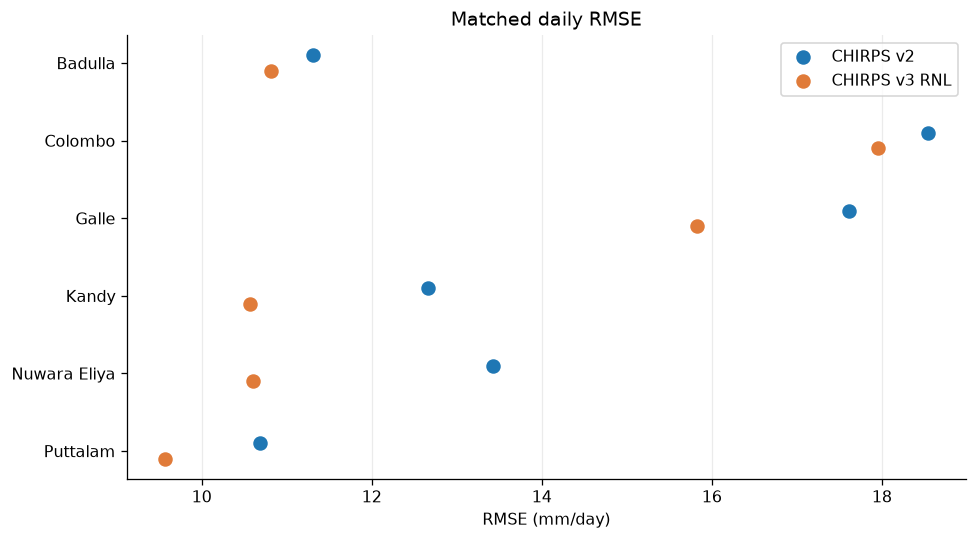

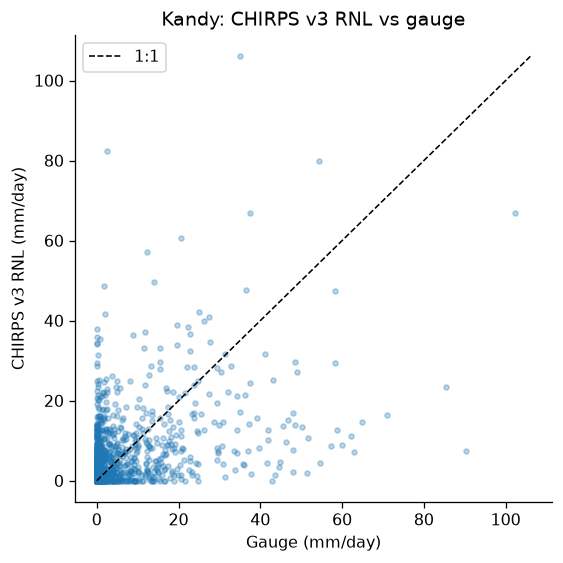

In [23]:
validation=period_rows(raw,VALID)
rows=[]
for st in STATIONS:
    x=validation[validation.Station==st]
    for name,col in PRODUCTS.items():
        rows.append({'Station':st,'Product':name,'start':VALID[0],'end':VALID[1],**paired_scores(x.Rainfall_mm,x[col])})
daily_scores=pd.DataFrame(rows)
p=daily_scores.pivot(index='Station',columns='Product',values='RMSE')
improve=(100*(p['CHIRPS v2']-p['CHIRPS v3 RNL'])/p['CHIRPS v2']).rename('V3_RMSE_improvement_percent')
print('Daily RMSE/MAE/Bias: mm/day. Correlations: unitless.');display(daily_scores.round(3));display(improve.round(2))
daily_scores.to_csv(TABDIR/'02_daily_validation_scores.csv',index=False); improve.to_csv(TABDIR/'03_v3_improvement_percent.csv')
fig,ax=plot_metric_dotplot(daily_scores,save_as='01_daily_rmse_dotplot');plt.show()
fig,ax=plot_station_scatter(raw,station='Kandy',save_as='02_Kandy_v3_scatter');plt.show()


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def select_period(df, period):
    """
    Select observations within a specified date range.

    period = (start_date, end_date)
    Both dates are included.
    """
    start, end = period

    dates = pd.to_datetime(df["Date"])

    return df.loc[
        dates.between(start, end)
    ].copy()

def test_h1_rmse(data, period=VALID, n_boot=10000, seed=42):
    """Paired year-block bootstrap of v2 minus v3 daily RMSE."""

    rng = np.random.default_rng(seed)
    x = select_period(data, period).copy()

    x["Year"] = pd.to_datetime(x["Date"]).dt.year
    results = []

    for station in STATIONS:
        s = x[x["Station"] == station].copy()

        # Identical valid observations for both products
        s = s.dropna(subset=[
            "Rainfall_mm", "CHIRPS_mm", "CHIRPS_V3_mm"
        ])

        s = s[
            (s["Rainfall_mm"] >= 0) &
            (s["CHIRPS_mm"] >= 0) &
            (s["CHIRPS_V3_mm"] >= 0)
        ]

        year_blocks = [
            group for _, group in s.groupby("Year")
        ]

        n_years = len(year_blocks)

        def rmse_pair(frame):
            gauge = frame["Rainfall_mm"].to_numpy()
            v2 = frame["CHIRPS_mm"].to_numpy()
            v3 = frame["CHIRPS_V3_mm"].to_numpy()

            return (
                np.sqrt(np.mean((v2 - gauge)**2)),
                np.sqrt(np.mean((v3 - gauge)**2))
            )

        rmse_v2, rmse_v3 = rmse_pair(s)
        observed_reduction = rmse_v2 - rmse_v3

        boot = []

        for _ in range(n_boot):
            sampled = rng.integers(
                0, n_years, size=n_years
            )

            sample = pd.concat(
                [year_blocks[i] for i in sampled],
                ignore_index=True
            )

            b2, b3 = rmse_pair(sample)
            boot.append(b2 - b3)

        low, high = np.percentile(
            boot, [2.5, 97.5]
        )

        results.append({
            "Station": station,
            "n_days": len(s),
            "n_years": n_years,
            "RMSE_v2_mm_day": rmse_v2,
            "RMSE_v3_mm_day": rmse_v3,
            "RMSE_reduction_mm_day": observed_reduction,
            "Improvement_percent":
                100 * observed_reduction / rmse_v2,
            "CI_lower": low,
            "CI_upper": high,
            "CI_excludes_zero": low > 0 or high < 0
        })

    return pd.DataFrame(results)


h1_results = test_h1_rmse(raw)

display(h1_results.round(3))

h1_results.to_csv(
    TABDIR / "H1_RMSE_year_block_bootstrap.csv",
    index=False
)

,Station,n_days,n_years,RMSE_v2_mm_day,RMSE_v3_mm_day,RMSE_reduction_mm_day,Improvement_percent,CI_lower,CI_upper,CI_excludes_zero
0,Badulla,1461,4,11.305,10.820,0.485,4.288,-0.703,1.723,False
1,Colombo,1460,4,18.541,17.957,0.583,3.146,-0.603,2.644,False
2,Galle,1461,4,17.609,15.822,1.787,10.148,0.241,3.214,True
3,Kandy,1461,4,12.665,10.569,2.095,16.545,1.551,2.779,True
4,Nuwaraeliya,1458,4,13.430,10.606,2.824,21.030,1.273,3.927,True
5,Puttalam,1459,4,10.690,9.567,1.123,10.504,0.811,1.397,True


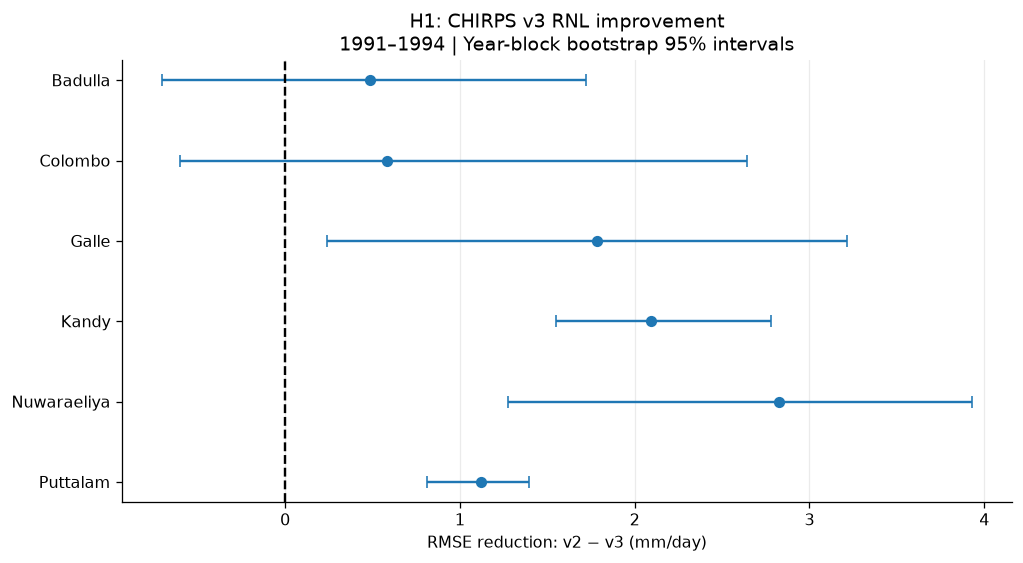

In [28]:
def plot_h1_improvement(h1_results):
    fig, ax = plt.subplots(figsize=(9, 5))

    d = h1_results.copy().reset_index(drop=True)
    y = np.arange(len(d))

    values = d["RMSE_reduction_mm_day"].to_numpy()
    lower = d["CI_lower"].to_numpy()
    upper = d["CI_upper"].to_numpy()

    errors = np.array([
        values - lower,
        upper - values
    ])

    ax.errorbar(
        values, y,
        xerr=errors,
        fmt="o",
        capsize=4
    )

    ax.axvline(0, color="black", linestyle="--")

    ax.set_yticks(y)
    ax.set_yticklabels(d["Station"])
    ax.invert_yaxis()

    ax.set_xlabel(
        "RMSE reduction: v2 − v3 (mm/day)"
    )
    ax.set_title(
        "H1: CHIRPS v3 RNL improvement\n"
        "1991–1994 | Year-block bootstrap 95% intervals"
    )

    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    return fig, ax


fig, ax = plot_h1_improvement(h1_results)
plt.show()

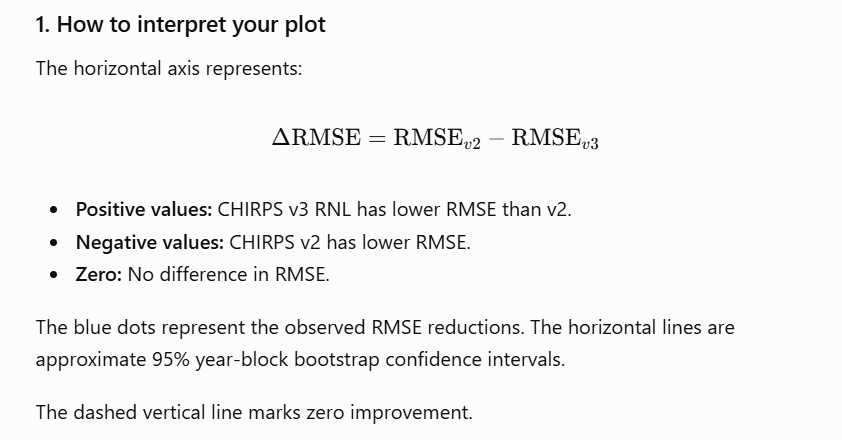

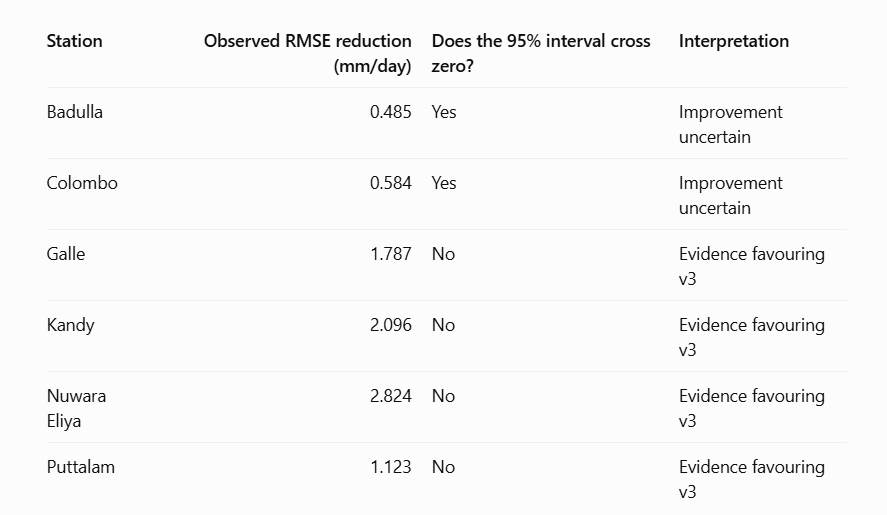

Badulla and Colombo: Although v3 has lower observed RMSE, the intervals extend below zero. We cannot confidently rule out no improvement using this analysis.

Galle, Kandy, Nuwara Eliya and Puttalam: The estimated confidence intervals lie entirely above zero, providing stronger evidence favouring v3 for daily RMSE.

Nuwara Eliya has the largest observed reduction, approximately 2.824 mm/day

he paired daily rainfall evaluation over 1991–1994 indicated that CHIRPS v3 RNL achieved lower RMSE than CHIRPS v2 at all six meteorological stations. The greatest absolute improvement occurred at Nuwara Eliya (2.824 mm/day), followed by Kandy (2.096 mm/day). An exploratory calendar-year block bootstrap with 10,000 resamples produced 95% confidence intervals for the RMSE reductions. These intervals were entirely positive at Galle, Kandy, Nuwara Eliya and Puttalam, whereas the intervals for Badulla and Colombo crossed zero. Thus, the results provide stronger evidence of improved daily RMSE at four stations, although inference is limited by the four-year validation period and the small number of independent annual blocks

In [37]:
#Your figure is already appropriate for a scientific report. I would make two small additions:
#1. Add the number of paired days and resampling blocks to the caption.
#2. Report the numerical lower and upper confidence limits in a separate table rather than asking readers to estimate them from the graph.
display(
    h1_results[
        [
            "Station",
            "n_days",
            "n_years",
            "RMSE_reduction_mm_day",
            "Improvement_percent",
            "CI_lower",
            "CI_upper"
        ]
    ].round(3)
)

,Station,n_days,n_years,RMSE_reduction_mm_day,Improvement_percent,CI_lower,CI_upper
0,Badulla,1461,4,0.485,4.288,-0.703,1.723
1,Colombo,1460,4,0.583,3.146,-0.603,2.644
2,Galle,1461,4,1.787,10.148,0.241,3.214
3,Kandy,1461,4,2.095,16.545,1.551,2.779
4,Nuwaraeliya,1458,4,2.824,21.030,1.273,3.927
5,Puttalam,1459,4,1.123,10.504,0.811,1.397


## 4. Temporal accumulation — H2
Whether the daily, pentad, weekly and monthly correlation comparisons are statistically fair.
A pentad is not a five-day forecast. It is a calendar-based rainfall accumulation interval. Most pentads contain five days, but the last pentad of a month may contain more or fewer.

**Important distinction:** a CHIRPS *calendar pentad* uses days 1–5, 6–10, 11–15, 16–20, 21–25 and **26 to month-end**. The last interval is 3–6 days long depending on month; label the duration. Weekly bins use fixed Monday–Sunday weeks, and monthly bins use calendar months.

We include an interval only if *every calendar date* in it has a matched gauge, v2 and v3 record. This prevents treating a partial sum as a complete 5-day/weekly/monthly total. Scores at these scales are in **mm/interval**, not mm/day. A higher correlation after aggregation does not establish an improvement in absolute error or prove a causal mechanism.

**Literature:** Funk et al. (2015) for CHIRPS and Funk et al. (2026) for v3 RNL pentad-to-daily disaggregation. The final calendar pentad is not a fixed five-day forecast.

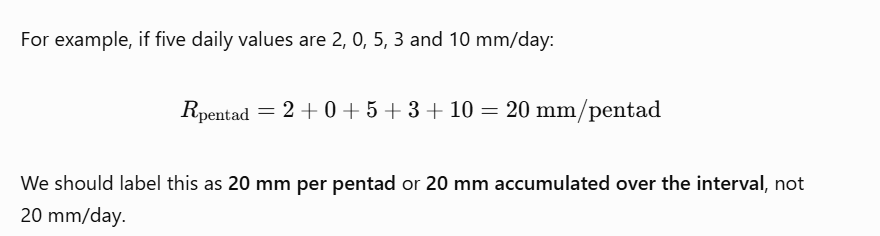

In [11]:
def add_interval_ids(d,scale):
    x=d.copy(); dt=x.Date.dt
    if scale=='daily':
        x['interval']=x.Date; x['expected_days']=1
    elif scale=='pentad':
        x['pentad_number']=np.minimum((dt.day.sub(1)//5)+1,6)
        x['interval']=dt.to_period('M').dt.to_timestamp()+pd.to_timedelta((x.pentad_number-1)*5,unit='D')
        x['expected_days']=np.where(x.pentad_number==6,dt.days_in_month-25,5)
    elif scale=='weekly':
        x['interval']=x.Date-pd.to_timedelta(dt.weekday,unit='D')
        x['expected_days']=7
    elif scale=='monthly':
        x['interval']=dt.to_period('M').dt.to_timestamp()
        x['expected_days']=dt.days_in_month
    else:raise ValueError(scale)
    return x

def complete_intervals(d,scale): #Its job is to assign each daily observation to a time interval
    x=add_interval_ids(d,scale)
    g=x.groupby(['Station','interval'],as_index=False).agg(n_days=('Date','nunique'),expected_days=('expected_days','first'),Gauge_mm=('Rainfall_mm','sum'),V2_mm=('CHIRPS_mm','sum'),V3_mm=('CHIRPS_V3_mm','sum'))
    g=g[g.n_days==g.expected_days].copy()
    g['scale']=scale
    return g

# IMPORTANT: build full-interval aggregates first and then restrict by period dates.
# This prevents using an incomplete weekly bin at the start/end of validation.
scales={s:complete_intervals(raw,s) for s in ['daily','pentad','weekly','monthly']}
scales['daily'].head()

,Station,interval,n_days,expected_days,Gauge_mm,V2_mm,V3_mm,scale
0,Badulla,1981-01-01,1,1,12.4,58.288452,3.405559,daily
1,Badulla,1981-01-02,1,1,16.4,17.188242,18.971624,daily
2,Badulla,1981-01-03,1,1,37.2,9.529316,10.299603,daily
3,Badulla,1981-01-04,1,1,6.4,6.546365,4.116186,daily
4,Badulla,1981-01-05,1,1,0.0,0.000000,3.542490,daily


,Station,Product,scale,n,unit,RMSE,MAE,Bias,Pearson_r,Spearman_rho
0,Badulla,CHIRPS v2,daily,1461,mm/day,11.305,5.355,0.083,0.467,0.404
1,Badulla,CHIRPS v3 RNL,daily,1461,mm/day,10.820,5.243,0.320,0.413,0.548
2,Colombo,CHIRPS v2,daily,1460,mm/day,18.541,7.397,-1.093,0.429,0.436
3,Colombo,CHIRPS v3 RNL,daily,1460,mm/day,17.957,6.729,-0.503,0.461,0.566
4,Galle,CHIRPS v2,daily,1461,mm/day,17.609,7.718,-0.660,0.387,0.393
5,Galle,CHIRPS v3 RNL,daily,1461,mm/day,15.822,7.072,0.292,0.418,0.532
6,Kandy,CHIRPS v2,daily,1461,mm/day,12.665,6.291,0.010,0.373,0.344
7,Kandy,CHIRPS v3 RNL,daily,1461,mm/day,10.569,5.458,0.223,0.440,0.520
8,Nuwaraeliya,CHIRPS v2,daily,1458,mm/day,13.430,6.805,0.013,0.357,0.345
9,Nuwaraeliya,CHIRPS v3 RNL,daily,1458,mm/day,10.606,5.229,-0.372,0.435,0.602


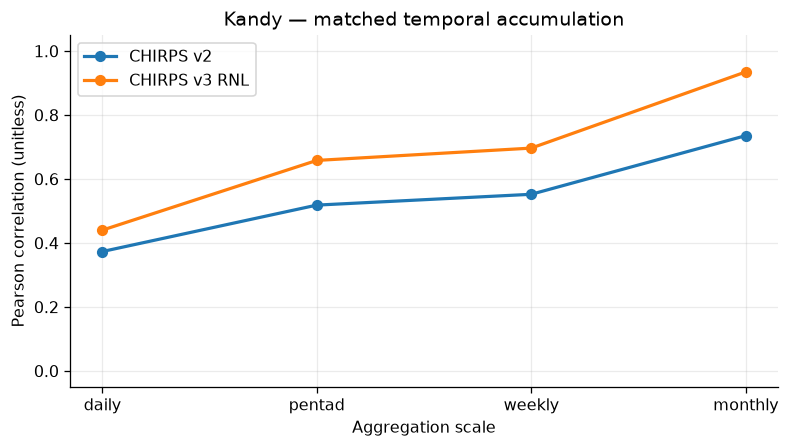

In [13]:
def score_temporal_scales(scales,period=VALID):
    rows=[] #scale will accept 4 datasets created early
    for scale,a in scales.items():
        x=a[a.interval.between(pd.Timestamp(period[0]),pd.Timestamp(period[1]))] #selected requited evalavation periond 1991-1994 real time by defaults
        # exclude a boundary week if it extends beyond the date period
        x=x[x.interval+pd.to_timedelta(x.expected_days-1,unit='D')<=pd.Timestamp(period[1])]
        for st in STATIONS:
            z=x[x.Station==st]
            for p,col in [('CHIRPS v2','V2_mm'),('CHIRPS v3 RNL','V3_mm')]:
                rows.append(dict(Station=st,Product=p,scale=scale,unit=('mm/day' if scale=='daily' else 'mm/interval'),**paired_scores(z.Gauge_mm,z[col])))
    return pd.DataFrame(rows)
scale_scores=score_temporal_scales(scales)
display(scale_scores[['Station','Product','scale','n','unit','RMSE','MAE','Bias','Pearson_r','Spearman_rho']].round(3))
scale_scores.to_csv(TABDIR/'04_temporal_scales_validation_scores.csv',index=False)
fig,ax=plot_scale_correlations(scale_scores,station='Kandy',save_as='03_Kandy_correlation_by_scale');plt.show()


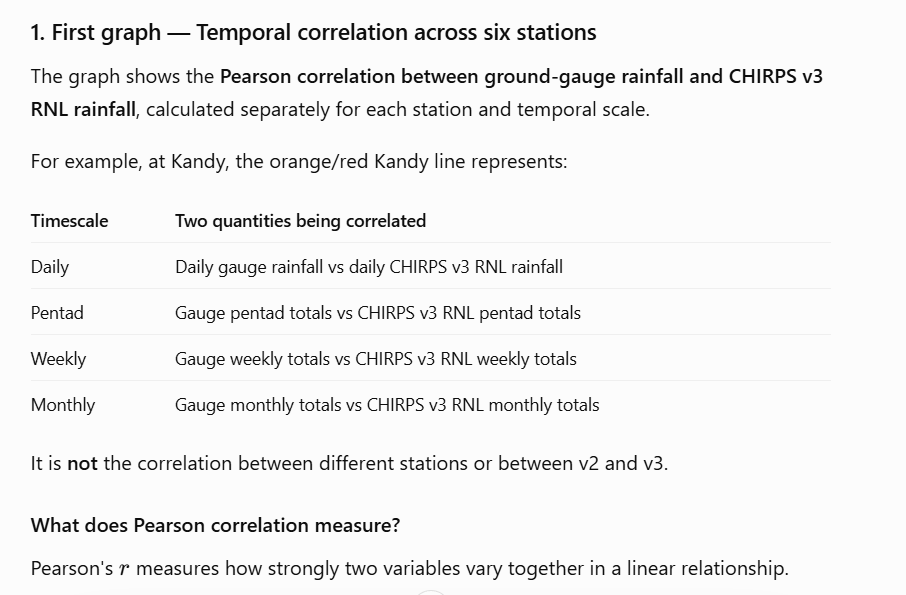

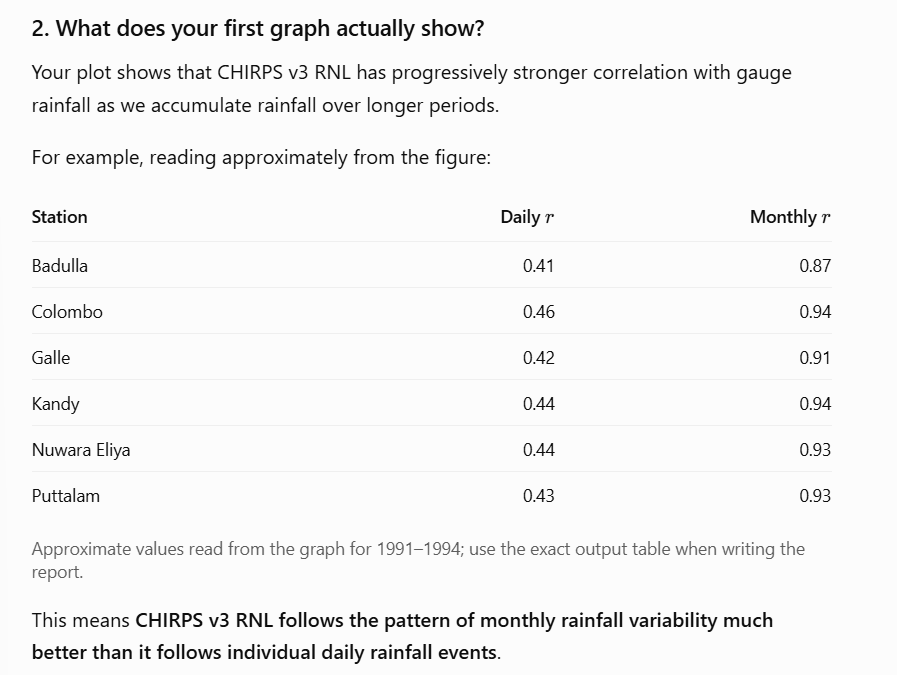

This means CHIRPS v3 RNL follows the pattern of monthly rainfall variability much better than it follows individual daily rainfall events.
he daily estimates are poorly aligned, but the three-day totals are identical.

When accumulated, some daily timing errors cancel.

Therefore, increasing correlation at longer timescales suggests that CHIRPS captures broad rainfall variation more reliably than exact daily timing.

However, it does not necessarily demonstrate that monthly estimates have lower absolute error.


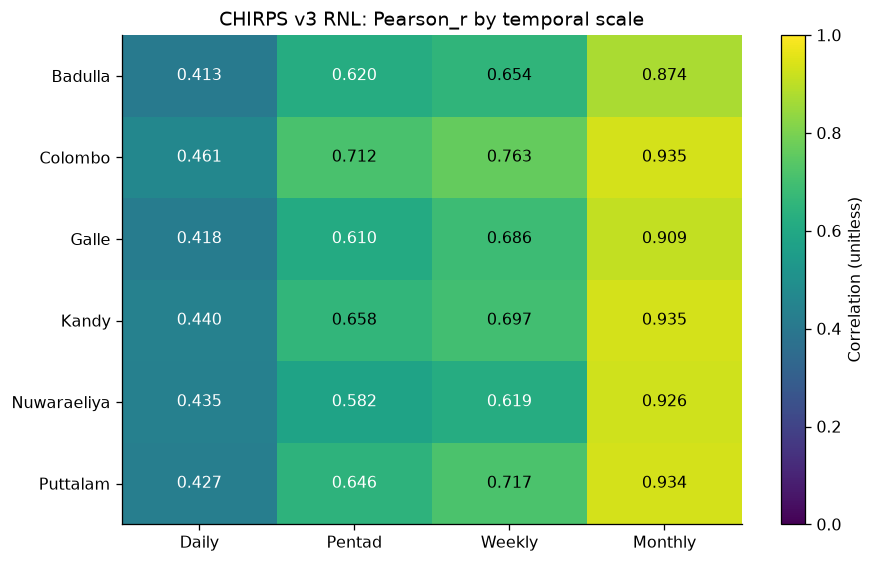

In [42]:
#correlation heat map for all 6 stations
def plot_temporal_correlation_heatmap(
    scores,
    product="CHIRPS v3 RNL",
    method="Pearson_r"
):
    import matplotlib.pyplot as plt
    import numpy as np

    order = ["daily", "pentad", "weekly", "monthly"]

    table = (
        scores[scores["Product"] == product]
        .pivot(
            index="Station",
            columns="scale",
            values=method
        )
        .reindex(columns=order)
    )

    values = table.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(8, 5))

    im = ax.imshow(
        values,
        vmin=0,
        vmax=1,
        cmap="viridis",
        aspect="auto"
    )

    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(
        [x.capitalize() for x in table.columns]
    )

    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]

            if np.isfinite(value):
                ax.text(
                    j, i, f"{value:.3f}",
                    ha="center",
                    va="center",
                    color="white" if value < 0.65 else "black"
                )

    ax.set_title(
        f"{product}: {method} by temporal scale"
    )

    fig.colorbar(im, ax=ax, label="Correlation (unitless)")
    fig.tight_layout()

    return fig, ax


fig, ax = plot_temporal_correlation_heatmap(
    scale_scores,
    product="CHIRPS v3 RNL",
    method="Pearson_r"
)

plt.show()

H2: Agreement between CHIRPS rainfall estimates and ground observations increases with temporal aggregation.

Your first graph provides descriptive support for this hypothesis at all six stations.

However, to test the hypothesis more rigorously, we need to examine:
1. Pearson and Spearman correlations at each scale.
2. Error magnitudes and relative bias at each scale.
3. Whether the apparent improvements persist across different years.
4. Confidence intervals accounting for temporal dependence.
We should be careful with statistical comparisons because daily, pentad and monthly values have different aggregation lengths and sample sizes.
Temporal aggregation increased the Pearson correlation between CHIRPS v3 RNL precipitation estimates and ground-gauge observations at all six meteorological stations during 1991–1994. Correlations were moderate at the daily scale (approximately 0.41–0.46) and substantially stronger for complete monthly totals (approximately 0.87–0.94). This indicates improved representation of accumulated rainfall variability at longer temporal scales. However, the increasing correlation does not independently demonstrate reduced rainfall-estimation error; additional assessment of normalized error and accumulated rainfall bias is required.

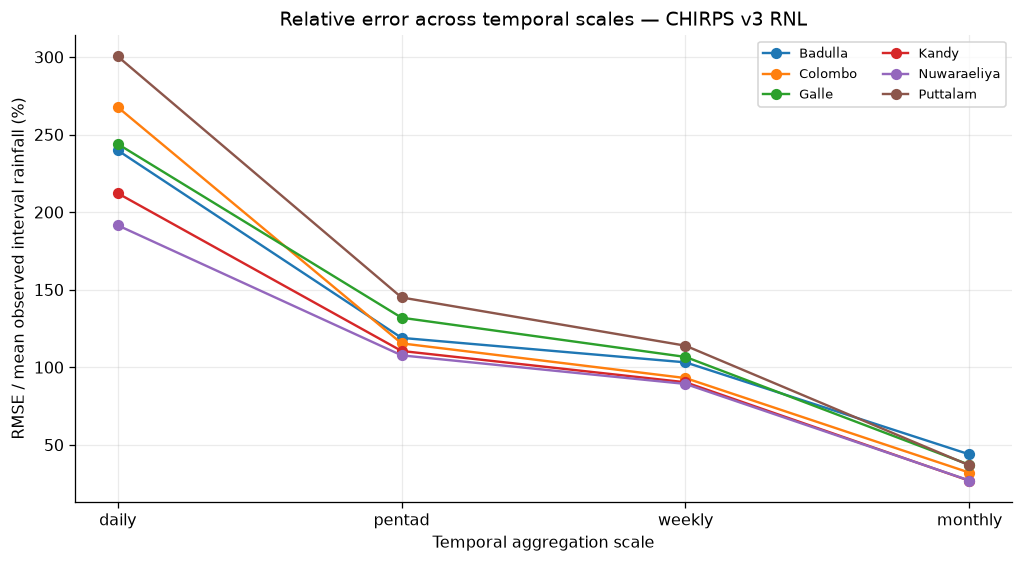

In [47]:
#Normalize RMSE dot plot
def plot_temporal_nrmse(scores, product="CHIRPS v3 RNL"):
    import matplotlib.pyplot as plt
    import numpy as np

    x = scores[scores["Product"] == product].copy()

    x["NRMSE_percent"] = np.where(
        x["Gauge_mean"] > 0,
        100 * x["RMSE"] / x["Gauge_mean"],
        np.nan
    )

    order = ["daily", "pentad", "weekly", "monthly"]

    fig, ax = plt.subplots(figsize=(9, 5))

    for station, group in x.groupby("Station"):
        group = group.set_index("scale").reindex(order)

        ax.plot(
            order,
            group["NRMSE_percent"],
            marker="o",
            label=station
        )

    ax.set_xlabel("Temporal aggregation scale")
    ax.set_ylabel(
        "RMSE / mean observed interval rainfall (%)"
    )
    ax.set_title(
        f"Relative error across temporal scales — {product}"
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)

    fig.tight_layout()
    return fig, ax


fig, ax = plot_temporal_nrmse(scale_scores)
plt.show() #each line shows how strongly that CHIRPS version correlates with ground-gauge rainfall at different temporal scales.

he temporal aggregation analysis indicates that CHIRPS v2 and v3 RNL exhibit stronger correlations with observed rainfall at longer accumulation periods. At Kandy, CHIRPS v3 RNL correlation increases from approximately 0.440 for daily rainfall to approximately 0.935 for monthly totals. This suggests that broader-scale rainfall variability is better represented than individual daily rainfall events. However, higher correlation does not necessarily indicate lower accumulated rainfall error. Further evaluation using normalized error, relative bias and temporal uncertainty is required before concluding that any particular timescale provides more accurate rainfall estimates.

## 5. Reusable figures: all-station temporal correlations and monthly totals
We plot **one figure per outcome**, with clear units. The monthly chart uses only complete months. Note that high monthly Pearson correlation (often ~0.8–0.9) is not the same thing as low monthly RMSE.


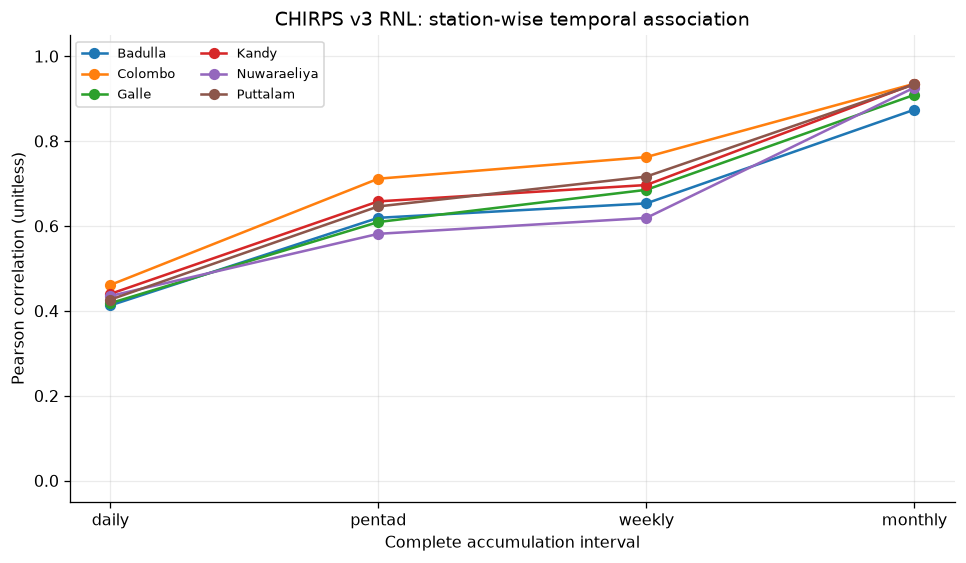

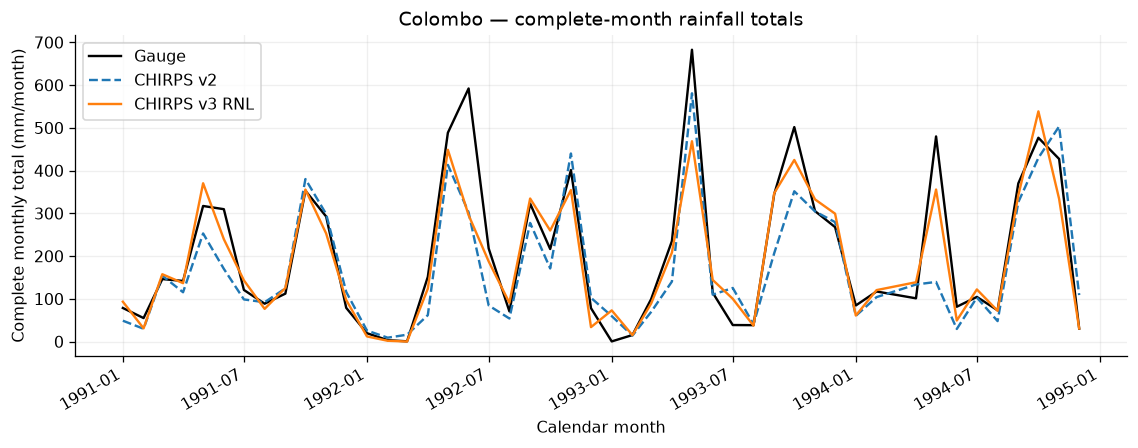

,Station,Product,n_complete_months,RMSE_mm_per_month,Pearson_r
36,Badulla,CHIRPS v2,48,73.860,0.811
37,Badulla,CHIRPS v3 RNL,48,60.301,0.874
38,Colombo,CHIRPS v2,47,87.651,0.886
39,Colombo,CHIRPS v3 RNL,47,66.126,0.935
40,Galle,CHIRPS v2,48,98.912,0.823
41,Galle,CHIRPS v3 RNL,48,73.395,0.909
42,Kandy,CHIRPS v2,48,94.232,0.736
43,Kandy,CHIRPS v3 RNL,48,40.821,0.935
44,Nuwaraeliya,CHIRPS v2,45,78.265,0.747
45,Nuwaraeliya,CHIRPS v3 RNL,45,45.776,0.926


In [15]:
def plot_all_scale_correlations(t,product='CHIRPS v3 RNL',save_as=None):
    x=t[t.Product==product].copy(); order=['daily','pentad','weekly','monthly']
    fig,ax=plt.subplots(figsize=(8.5,5))
    for st,g in x.groupby('Station'):
        g=g.set_index('scale').reindex(order)
        ax.plot(order,g.Pearson_r,marker='o',linewidth=1.6,label=st)
    ax.set(ylabel='Pearson correlation (unitless)',xlabel='Complete accumulation interval',title=f'{product}: station-wise temporal association');ax.set_ylim(-.05,1.05);ax.grid(alpha=.25);ax.legend(ncol=2,fontsize=8);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_monthly_timeseries(months,station='Kandy',period=VALID,save_as=None):
    z=months[(months.Station==station)&months.interval.between(pd.Timestamp(period[0]),pd.Timestamp(period[1]))]
    fig,ax=plt.subplots(figsize=(10,4))
    for col,label,sty in [('Gauge_mm','Gauge','k-'),('V2_mm','CHIRPS v2','C0--'),('V3_mm','CHIRPS v3 RNL','C1-')]:
        ax.plot(z.interval,z[col],sty,linewidth=1.5,label=label)
    ax.set(xlabel='Calendar month',ylabel='Complete monthly total (mm/month)',title=f'{station} — complete-month rainfall totals');ax.legend();ax.grid(alpha=.2);fig.autofmt_xdate();fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax
fig,ax=plot_all_scale_correlations(scale_scores,save_as='04_all_station_correlation_by_scale');plt.show()
fig,ax=plot_monthly_timeseries(scales['monthly'],station='Colombo',save_as='05_Colombo_complete_monthly_totals');plt.show()
monthly_table=scale_scores[scale_scores.scale=='monthly'][['Station','Product','n','RMSE','Pearson_r']].copy()
monthly_table=monthly_table.rename(columns={'n':'n_complete_months','RMSE':'RMSE_mm_per_month'})
display(monthly_table.round(3));monthly_table.to_csv(TABDIR/'05_monthly_validation_summary.csv',index=False)


## 6. Pentad timing diagnostic — H4 (exploratory)
For a complete pentad with positive observed and satellite totals, define within-pentad daily allocation fractions:
\[f_{G,d}=G_d/\sum_{j\in p}G_j,\quad f_{S,d}=S_d/\sum_{j\in p}S_j.\]
Compare daily fraction MAE, *not* a fraction when the denominator is zero. Fraction error does **not** identify whether the total or the within-pentad timing caused a daily error. We will compare both independently. Only completely paired pentads are used.


,Station,Product,n_days_valid,fraction_MAE
0,Badulla,CHIRPS v2,846,0.201
1,Badulla,CHIRPS v3 RNL,968,0.183
2,Colombo,CHIRPS v2,899,0.211
3,Colombo,CHIRPS v3 RNL,1074,0.196
4,Galle,CHIRPS v2,798,0.206
5,Galle,CHIRPS v3 RNL,1081,0.187
6,Kandy,CHIRPS v2,772,0.215
7,Kandy,CHIRPS v3 RNL,1002,0.186
8,Nuwaraeliya,CHIRPS v2,853,0.209
9,Nuwaraeliya,CHIRPS v3 RNL,1115,0.163


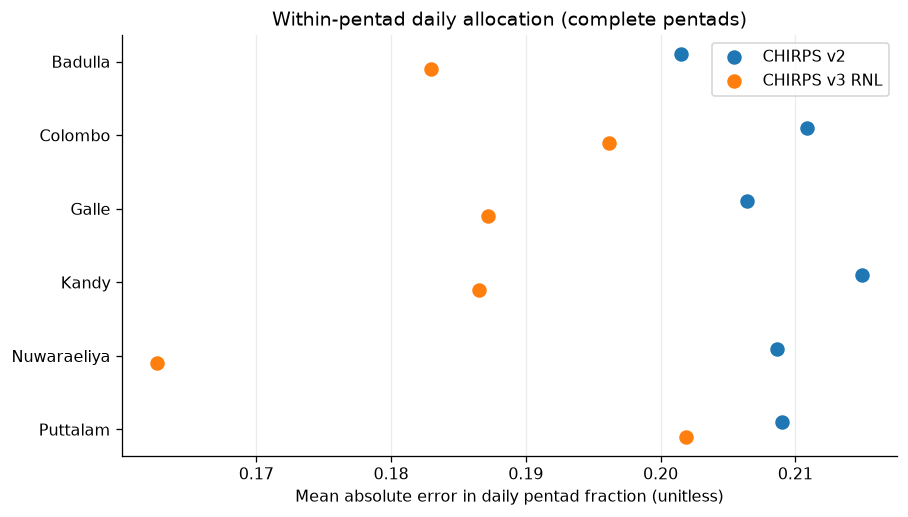

In [17]:
def pentad_allocation_scores(d,period=VALID):
    x=add_interval_ids(d,'pentad')
    x['n_days']=x.groupby(['Station','interval']).Date.transform('nunique')
    x=x[(x.n_days==x.expected_days)&x.interval.between(pd.Timestamp(period[0]),pd.Timestamp(period[1]))].copy()
    # check that all dates in the interval also lie within the validation period
    x=x[x.interval+pd.to_timedelta(x.expected_days-1,unit='D')<=pd.Timestamp(period[1])]
    for col in ['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']:
        den=x.groupby(['Station','interval'])[col].transform('sum')
        x[col+'_fraction']=np.where(den>0,x[col]/den,np.nan)
    rows=[]
    for st,g in x.groupby('Station'):
        for p,c in PRODUCTS.items():
            a=g['Rainfall_mm_fraction'].to_numpy(float);b=g[c+'_fraction'].to_numpy(float)
            ok=np.isfinite(a)&np.isfinite(b)
            rows.append(dict(Station=st,Product=p,n_days_valid=int(ok.sum()),fraction_MAE=float(np.mean(np.abs(a[ok]-b[ok]))) if ok.any() else np.nan))
    return pd.DataFrame(rows),x
alloc_scores,alloc_days=pentad_allocation_scores(raw)
display(alloc_scores.round(3));alloc_scores.to_csv(TABDIR/'06_pentad_allocation_fraction_mae.csv',index=False)

def plot_allocation_dotplot(t,save_as=None):
    fig,ax=plt.subplots(figsize=(8,4.6))
    for k,p in enumerate(PRODUCTS):
        z=t[t.Product==p].set_index('Station').reindex(STATIONS)
        ax.scatter(z.fraction_MAE,np.arange(len(STATIONS))+(-.1 if k==0 else .1),label=p,s=65)
    ax.set_yticks(range(len(STATIONS)));ax.set_yticklabels(STATIONS);ax.invert_yaxis()
    ax.set(xlabel='Mean absolute error in daily pentad fraction (unitless)',title='Within-pentad daily allocation (complete pentads)');ax.grid(axis='x',alpha=.25);ax.legend();fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax
fig,ax=plot_allocation_dotplot(alloc_scores,save_as='06_pentad_fraction_mae');plt.show()


In [85]:
#corrected H4

# ==========================================================
# H4 — MATCHED WITHIN-PENTAD ALLOCATION COMPARISON
# Validation period: 1991–1994
# Both products evaluated on identical eligible days
# ==========================================================

def matched_pentad_allocation_scores(alloc_days):

    gauge_col = "Rainfall_mm_fraction"
    v2_col = "CHIRPS_mm_fraction"
    v3_col = "CHIRPS_V3_mm_fraction"

    # Keep only days belonging to complete pentads
    # where all three allocation fractions are defined.
    common = alloc_days.dropna(
        subset=[gauge_col, v2_col, v3_col]
    ).copy()

    # Explicitly require entire eligible pentads.
    group_cols = ["Station", "interval"]

    counts = common.groupby(group_cols)["Date"].transform(
        "nunique"
    )

    common = common[
        counts == common["expected_days"]
    ].copy()

    rows = []

    for station in STATIONS:

        s = common[common["Station"] == station].copy()

        gauge = s[gauge_col].to_numpy(float)
        v2 = s[v2_col].to_numpy(float)
        v3 = s[v3_col].to_numpy(float)

        mae_v2 = np.mean(np.abs(gauge - v2))
        mae_v3 = np.mean(np.abs(gauge - v3))

        rows.append({
            "Station": station,
            "n_matched_days": len(s),
            "n_matched_pentads": s["interval"].nunique(),
            "V2_fraction_MAE": mae_v2,
            "V3_fraction_MAE": mae_v3,
            "MAE_reduction": mae_v2 - mae_v3,
            "Improvement_percent":
                100 * (mae_v2 - mae_v3) / mae_v2
                if mae_v2 > 0 else np.nan
        })

    return pd.DataFrame(rows), common


h4_matched, h4_common = matched_pentad_allocation_scores(
    alloc_days
)

display(h4_matched.round(4))

h4_matched.to_csv(
    TABDIR / "H4_matched_pentad_allocation_scores.csv",
    index=False
)


,Station,n_matched_days,n_matched_pentads,V2_fraction_MAE,V3_fraction_MAE,MAE_reduction,Improvement_percent
0,Badulla,791,155,0.2007,0.1845,0.0162,8.0943
1,Colombo,879,173,0.2087,0.1937,0.0150,7.1970
2,Galle,761,150,0.2042,0.1754,0.0288,14.1106
3,Kandy,741,146,0.2147,0.1856,0.0291,13.5429
4,Nuwaraeliya,843,166,0.2067,0.1574,0.0492,23.8231
5,Puttalam,570,112,0.2065,0.1962,0.0103,4.9912


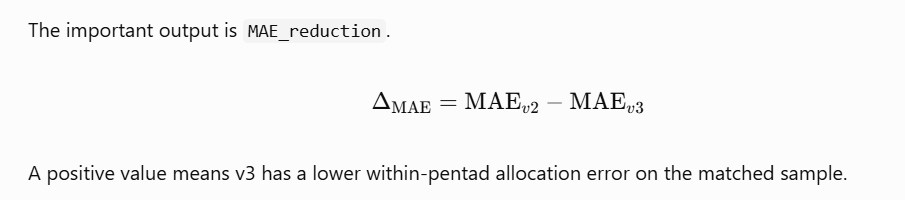

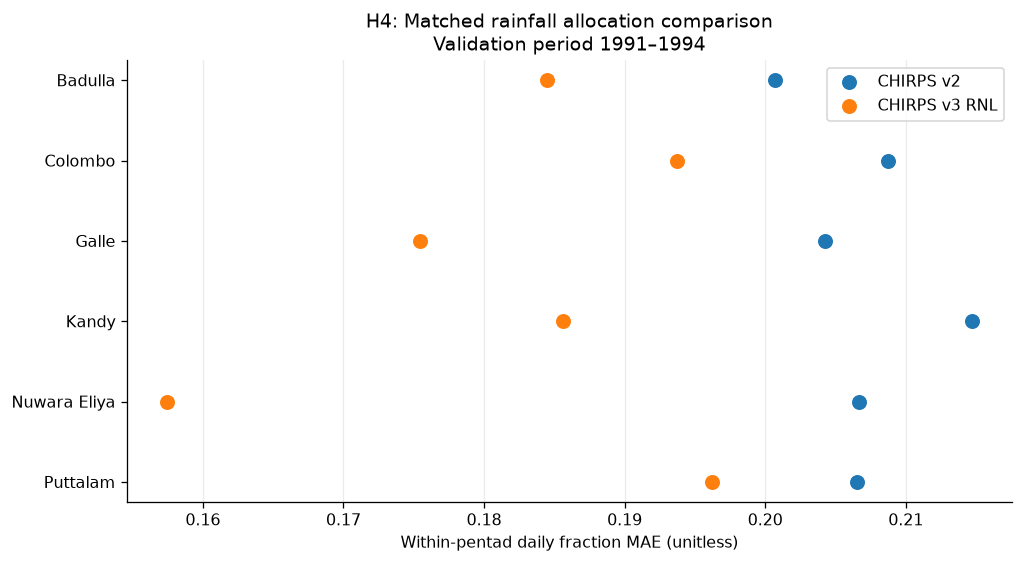

In [88]:
#plotting corrected H4 results
def plot_h4_matched_allocation(results):

    fig, ax = plt.subplots(figsize=(9, 5))

    y = np.arange(len(results))

    ax.scatter(
        results["V2_fraction_MAE"],
        y,
        label="CHIRPS v2",
        s=70
    )

    ax.scatter(
        results["V3_fraction_MAE"],
        y,
        label="CHIRPS v3 RNL",
        s=70
    )

    ax.set_yticks(y)
    ax.set_yticklabels(
        results["Station"].replace({
            "Nuwaraeliya": "Nuwara Eliya"
        })
    )

    ax.invert_yaxis()

    ax.set_xlabel(
        "Within-pentad daily fraction MAE (unitless)"
    )

    ax.set_title(
        "H4: Matched rainfall allocation comparison\n"
        "Validation period 1991–1994"
    )

    ax.legend()
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    return fig, ax


fig, ax = plot_h4_matched_allocation(h4_matched)
plt.show()


In [90]:
#automatic H4 conclusion test
n_better = (
    h4_matched["MAE_reduction"] > 0
).sum()

print(
    f"CHIRPS v3 RNL has lower matched allocation "
    f"MAE at {n_better}/6 stations."
)

display(
    h4_matched[
        [
            "Station",
            "n_matched_pentads",
            "V2_fraction_MAE",
            "V3_fraction_MAE",
            "Improvement_percent"
        ]
    ].round(4)
)

CHIRPS v3 RNL has lower matched allocation MAE at 6/6 stations.


,Station,n_matched_pentads,V2_fraction_MAE,V3_fraction_MAE,Improvement_percent
0,Badulla,155,0.2007,0.1845,8.0943
1,Colombo,173,0.2087,0.1937,7.1970
2,Galle,150,0.2042,0.1754,14.1106
3,Kandy,146,0.2147,0.1856,13.5429
4,Nuwaraeliya,166,0.2067,0.1574,23.8231
5,Puttalam,112,0.2065,0.1962,4.9912


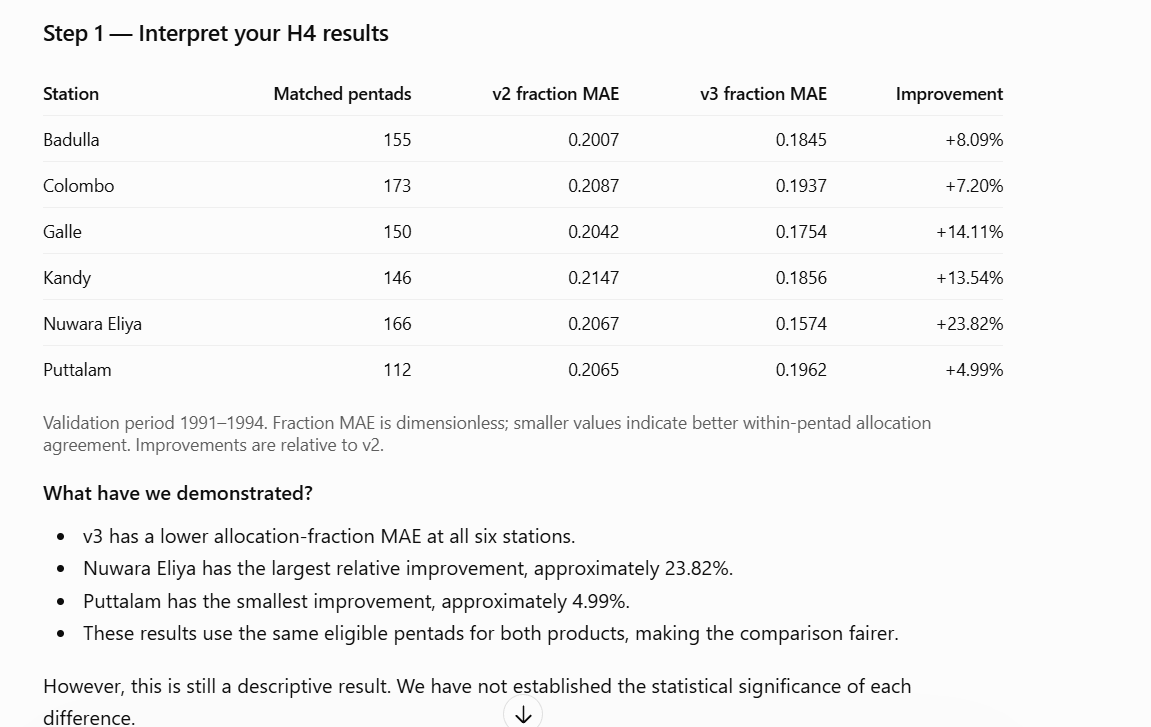

### H4 — Within-Pentad Rainfall Allocation

**Hypothesis:** CHIRPS v3 RNL distributes rainfall within calendar pentads more accurately than CHIRPS v2.

Daily rainfall allocation was evaluated by normalizing each day's rainfall by the total rainfall of its corresponding complete pentad. Gauge, CHIRPS v2 and CHIRPS v3 RNL allocation fractions were compared on identical eligible pentads during the 1991–1994 validation period.

CHIRPS v3 RNL achieved lower daily allocation-fraction MAE at all six meteorological stations. Relative improvements ranged from 4.99% at Puttalam to 23.82% at Nuwara Eliya. The largest reductions were observed at Nuwara Eliya (0.2067 to 0.1574), Galle (0.2042 to 0.1754) and Kandy (0.2147 to 0.1856).

These results indicate that CHIRPS v3 RNL better reproduces the relative distribution of rainfall among days within eligible pentads. However, allocation-fraction MAE measures the timing and proportional distribution of rainfall rather than the accuracy of pentad rainfall totals. A product may correctly distribute rainfall fractions but still overestimate or underestimate the accumulated rainfall amount.

Furthermore, pentads for which allocation fractions could not be defined, including zero-total pentads, were excluded. Statistical uncertainty has not yet been quantified.

**Conclusion:** H4 is descriptively supported at all six stations. The matched analysis indicates that CHIRPS v3 RNL improves within-pentad rainfall allocation compared with v2, motivating further investigation of pentad-level rainfall correction and redistribution.

# normaliz accuracy statistics
notebook already contains scale_scores, so we can use the values you calculated without repeating anything. \(\overline G\) is the mean observed rainfall total at that particular scale (G bar)

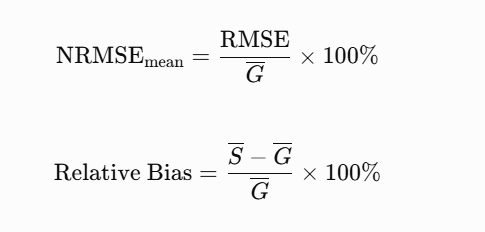

In [56]:

# ==========================================================
# H2: NORMALIZED ERROR AND RELATIVE BIAS
# Validation: 1991–1994
# ==========================================================

h2_scores = scale_scores.copy()

# Use positive observed mean rainfall for normalization.
denominator = h2_scores["Gauge_mean"].where(
    h2_scores["Gauge_mean"] > 0
)

h2_scores["NRMSE_percent"] = (
    100 * h2_scores["RMSE"] / denominator
)

h2_scores["Relative_Bias_percent"] = (
    100 * h2_scores["Bias"] / denominator
)

h2_scores["NMAE_percent"] = (
    100 * h2_scores["MAE"] / denominator
)

scale_order = ["daily", "pentad", "weekly", "monthly"]

h2_scores["scale"] = pd.Categorical(
    h2_scores["scale"],
    categories=scale_order,
    ordered=True
)

columns = [
    "Station", "Product", "scale", "n",
    "Gauge_mean", "Product_mean",
    "RMSE", "MAE", "Bias",
    "NRMSE_percent", "NMAE_percent",
    "Relative_Bias_percent",
    "Pearson_r", "Spearman_rho"
]

h2_summary = h2_scores[columns].sort_values(
    ["Station", "Product", "scale"]
)

display(h2_summary.round(3))

h2_summary.to_csv(
    TABDIR / "H2_normalized_accuracy.csv",
    index=False
)


,Station,Product,scale,n,Gauge_mean,Product_mean,RMSE,MAE,Bias,NRMSE_percent,NMAE_percent,Relative_Bias_percent,Pearson_r,Spearman_rho
0,Badulla,CHIRPS v2,daily,1461,4.508,4.592,11.305,5.355,0.083,250.742,118.783,1.847,0.467,0.404
12,Badulla,CHIRPS v2,pentad,288,22.871,23.294,26.155,17.287,0.423,114.359,75.583,1.847,0.661,0.581
24,Badulla,CHIRPS v2,weekly,207,31.204,32.318,32.168,21.285,1.114,103.090,68.213,3.571,0.670,0.619
36,Badulla,CHIRPS v2,monthly,48,137.227,139.762,73.860,52.844,2.535,53.823,38.508,1.847,0.811,0.818
1,Badulla,CHIRPS v3 RNL,daily,1461,4.508,4.829,10.820,5.243,0.320,239.989,116.289,7.109,0.413,0.548
13,Badulla,CHIRPS v3 RNL,pentad,288,22.871,24.497,27.229,17.384,1.626,119.053,76.008,7.109,0.620,0.610
25,Badulla,CHIRPS v3 RNL,weekly,207,31.204,33.643,32.225,20.704,2.439,103.271,66.351,7.816,0.654,0.684
37,Badulla,CHIRPS v3 RNL,monthly,48,137.227,146.982,60.301,42.241,9.755,43.942,30.782,7.109,0.874,0.844
2,Colombo,CHIRPS v2,daily,1460,6.705,5.612,18.541,7.397,-1.093,276.525,110.320,-16.301,0.429,0.436
14,Colombo,CHIRPS v2,pentad,287,34.108,28.548,41.325,24.432,-5.560,121.156,71.632,-16.301,0.681,0.617


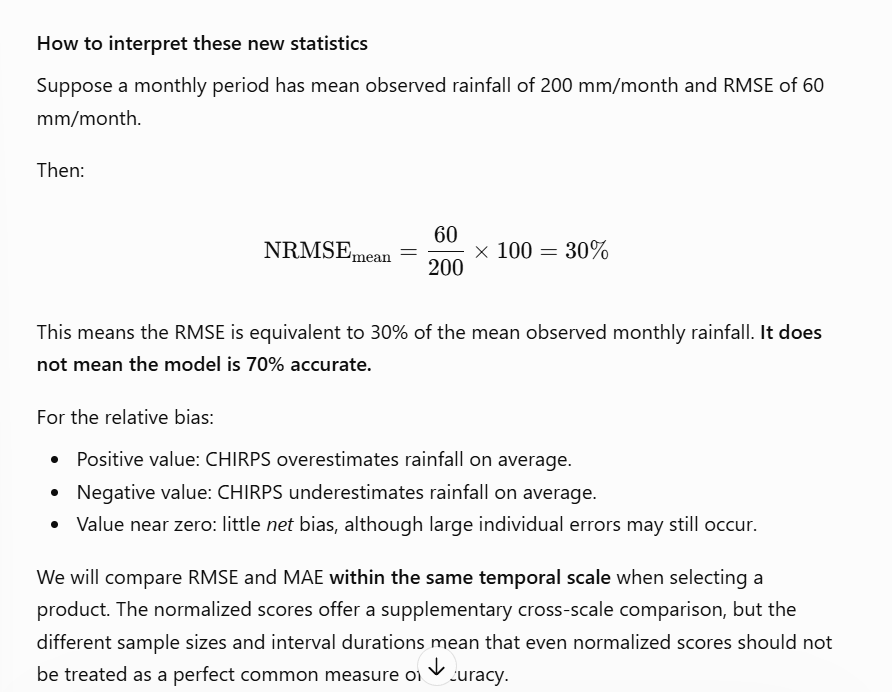

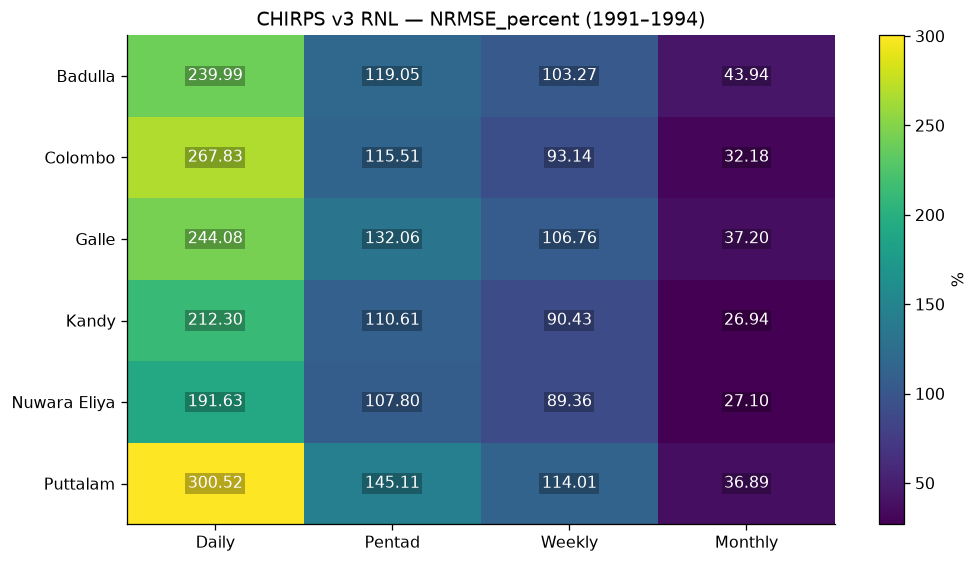

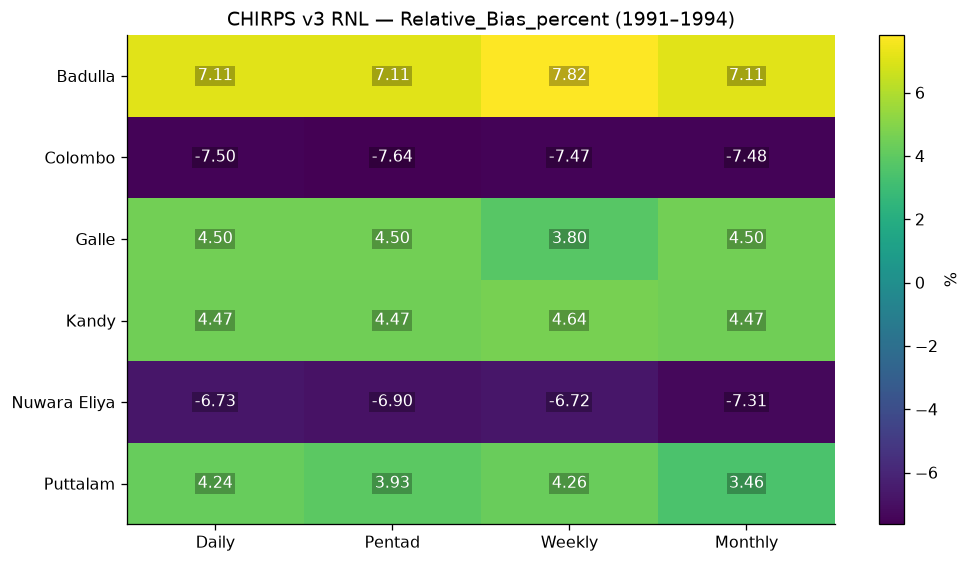

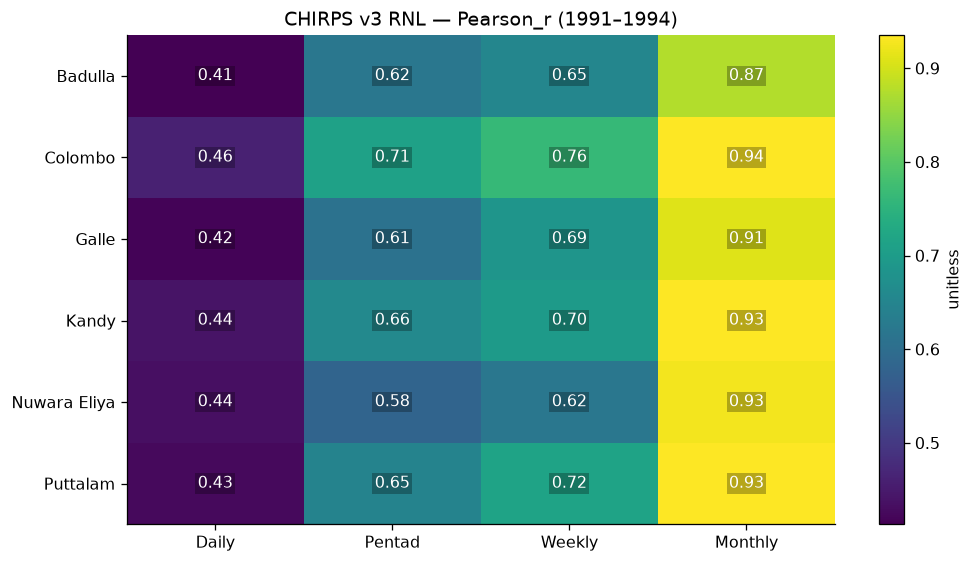

In [59]:
# statistical heatmap for H2 (to show 6 stations at once)

def plot_h2_heatmap(scores, metric="NRMSE_percent",
                    product="CHIRPS v3 RNL", save_as=None):

    order = ["daily", "pentad", "weekly", "monthly"]

    table = (
        scores[scores["Product"] == product]
        .pivot(index="Station", columns="scale", values=metric)
        .reindex(index=STATIONS, columns=order)
    )

    values = table.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(9, 5))
    im = ax.imshow(values, cmap="viridis", aspect="auto")

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([s.capitalize() for s in order])

    ax.set_yticks(range(len(STATIONS)))
    ax.set_yticklabels([
        "Nuwara Eliya" if s == "Nuwaraeliya" else s
        for s in STATIONS
    ])

    for i in range(len(STATIONS)):
        for j in range(len(order)):
            value = values[i, j]
            if np.isfinite(value):
                ax.text(j, i, f"{value:.2f}",
                        ha="center", va="center",
                        color="white",
                        bbox=dict(facecolor="black",
                                  alpha=0.28, edgecolor="none",
                                  pad=1.5))

    units = {
        "NRMSE_percent": "%",
        "Relative_Bias_percent": "%",
        "Pearson_r": "unitless",
        "Spearman_rho": "unitless"
    }

    ax.set_title(f"{product} — {metric} (1991–1994)")
    fig.colorbar(im, ax=ax, label=units.get(metric, metric))
    fig.tight_layout()

    if save_as:
        save_fig(fig, save_as)

    return fig, ax


# Plot 1: normalized error
fig, ax = plot_h2_heatmap(
    h2_scores,
    metric="NRMSE_percent",
    save_as="H2_normalized_RMSE_heatmap"
)
plt.show()

# Plot 2: relative bias
fig, ax = plot_h2_heatmap(
    h2_scores,
    metric="Relative_Bias_percent",
    save_as="H2_relative_bias_heatmap"
)
plt.show()

# Plot 3: Pearson correlation
fig, ax = plot_h2_heatmap(
    h2_scores,
    metric="Pearson_r",
    save_as="H2_Pearson_correlation_heatmap"
)
plt.show()



In [61]:
#Quantifying improvment daily to monthly

# ==========================================================
# H2: DAILY VERSUS MONTHLY COMPARISON
# ==========================================================

h2_daily_monthly = (
    h2_scores[
        h2_scores["scale"].isin(["daily", "monthly"])
    ]
    .pivot(
        index=["Station", "Product"],
        columns="scale",
        values=["Pearson_r", "NRMSE_percent"]
    )
)

h2_daily_monthly.columns = [
    f"{metric}_{scale}"
    for metric, scale in h2_daily_monthly.columns
]

h2_daily_monthly = h2_daily_monthly.reset_index()

h2_daily_monthly["Correlation_increase"] = (
    h2_daily_monthly["Pearson_r_monthly"]
    - h2_daily_monthly["Pearson_r_daily"]
)

h2_daily_monthly["NRMSE_reduction_pp"] = (
    h2_daily_monthly["NRMSE_percent_daily"]
    - h2_daily_monthly["NRMSE_percent_monthly"]
)

display(h2_daily_monthly.round(3))

h2_daily_monthly.to_csv(
    TABDIR / "H2_daily_vs_monthly_summary.csv",
    index=False
)


,Station,Product,Pearson_r_daily,Pearson_r_monthly,NRMSE_percent_daily,NRMSE_percent_monthly,Correlation_increase,NRMSE_reduction_pp
0,Badulla,CHIRPS v2,0.467,0.811,250.742,53.823,0.344,196.919
1,Badulla,CHIRPS v3 RNL,0.413,0.874,239.989,43.942,0.461,196.047
2,Colombo,CHIRPS v2,0.429,0.886,276.525,42.656,0.457,233.870
3,Colombo,CHIRPS v3 RNL,0.461,0.935,267.827,32.180,0.474,235.647
4,Galle,CHIRPS v2,0.387,0.823,271.651,50.133,0.437,221.518
5,Galle,CHIRPS v3 RNL,0.418,0.909,244.085,37.200,0.491,206.885
6,Kandy,CHIRPS v2,0.373,0.736,254.392,62.186,0.362,192.205
7,Kandy,CHIRPS v3 RNL,0.440,0.935,212.303,26.939,0.495,185.365
8,Nuwaraeliya,CHIRPS v2,0.357,0.747,242.662,46.340,0.391,196.322
9,Nuwaraeliya,CHIRPS v3 RNL,0.435,0.926,191.632,27.104,0.491,164.528


In [63]:
#Automatically summarize the H2 findings

# ==========================================================
# H2: DESCRIPTIVE HYPOTHESIS CONCLUSION
# ==========================================================

for product in PRODUCTS:
    d = h2_daily_monthly[
        h2_daily_monthly["Product"] == product
    ]

    correlation_improved = (
        d["Correlation_increase"] > 0
    ).sum()

    nrmse_improved = (
        d["NRMSE_reduction_pp"] > 0
    ).sum()

    print(f"\n{product}")
    print("-" * 45)

    print(
        f"Monthly Pearson correlation increased at "
        f"{correlation_improved}/{len(d)} stations."
    )

    print(
        f"Monthly normalized RMSE decreased at "
        f"{nrmse_improved}/{len(d)} stations."
    )

    print(
        "Mean daily Pearson r:",
        round(d["Pearson_r_daily"].mean(), 3)
    )

    print(
        "Mean monthly Pearson r:",
        round(d["Pearson_r_monthly"].mean(), 3)
    )

    print(
        "Mean daily NRMSE (%):",
        round(d["NRMSE_percent_daily"].mean(), 2)
    )

    print(
        "Mean monthly NRMSE (%):",
        round(d["NRMSE_percent_monthly"].mean(), 2)
    )

print("\nNote: These are descriptive findings,")
print("not formal statistical significance tests.")



CHIRPS v2
---------------------------------------------
Monthly Pearson correlation increased at 6/6 stations.
Monthly normalized RMSE decreased at 6/6 stations.
Mean daily Pearson r: 0.389
Mean monthly Pearson r: 0.807
Mean daily NRMSE (%): 271.96
Mean monthly NRMSE (%): 52.27

CHIRPS v3 RNL
---------------------------------------------
Monthly Pearson correlation increased at 6/6 stations.
Monthly normalized RMSE decreased at 6/6 stations.
Mean daily Pearson r: 0.433
Mean monthly Pearson r: 0.919
Mean daily NRMSE (%): 242.73
Mean monthly NRMSE (%): 34.04

Note: These are descriptive findings,
not formal statistical significance tests.


### Hypothesis H2 — Effect of Temporal Aggregation on CHIRPS Rainfall Accuracy

**Hypothesis:** Agreement between CHIRPS precipitation estimates and ground observations improves as daily rainfall is accumulated into pentad, weekly, and monthly totals.

The temporal aggregation analysis was conducted using paired CHIRPS v2, CHIRPS v3 RNL, and ground-gauge rainfall observations from six meteorological stations over the validation period 1991–1994. Only complete accumulation intervals were included to prevent incomplete rainfall totals from influencing the results.

Pearson correlation increased consistently from daily to monthly resolution for both CHIRPS products at all six stations. For CHIRPS v3 RNL, the mean station-wise Pearson correlation increased from 0.433 at daily resolution to 0.919 at monthly resolution. CHIRPS v2 exhibited a corresponding increase from 0.389 to 0.807. This suggests that CHIRPS captures broader-scale rainfall variability more successfully than individual daily rainfall fluctuations.

A similar pattern was observed in normalized rainfall errors. The mean normalized RMSE for CHIRPS v3 RNL decreased from 242.73% at daily resolution to 34.04% at monthly resolution, while the corresponding values for CHIRPS v2 decreased from 271.96% to 52.27%. All six stations exhibited reductions in normalized RMSE from daily to monthly aggregation for both products.

Nevertheless, temporal aggregation did not eliminate systematic rainfall bias. CHIRPS v3 RNL continued to underestimate monthly rainfall at Colombo and Nuwara Eliya, while positive relative biases were observed at several other stations. Furthermore, the decrease in normalized RMSE should be interpreted cautiously because temporal aggregation changes rainfall variability, interval duration, and sample size.

The increased monthly agreement is consistent with partial cancellation of daily estimation and timing errors during accumulation, although these results do not independently establish that daily timing errors are the principal cause.

**Conclusion:** Hypothesis H2 is descriptively supported across all six stations. Both CHIRPS versions demonstrate stronger correlation and lower mean-normalized error at monthly resolution than at daily resolution. CHIRPS v3 RNL generally provides better performance, particularly for monthly rainfall totals. However, further temporally aware uncertainty analysis is needed before treating these findings as statistically confirmed improvements. These results motivate investigating direct pentad and monthly calibration rather than relying exclusively on daily rainfall corrections.

## 7. Optional spatial-buffer study — H3
**No new extraction is needed.** The optional analysis checks the user's existing `data/chirps/buffered/` CSVs (`CHIRPS_Buffer_v2_YYYY.csv`, `CHIRPS_Buffer_v3rnl_YYYY.csv`) and computes a **matched** v2/v3 comparison only for years with both files present and all required columns.

A 5 km or 10 km buffer is a spatial mean across nearby pixels, **not** a higher-resolution rainfall observation. If files are absent, the notebook skips this section and clearly reports why. It will not silently treat a single year as 1991–1994 evidence.

In [19]:
def discover_buffer_files(root):
    dirs=[root/'data'/'chirps'/'buffered',root/'data'/'chirps',root/'data'/'processed',root,Path('/mnt/data')]
    found={}
    for yr in range(1981,2001):
        for version in ['v2','v3rnl']:
            filename=f'CHIRPS_Buffer_{version}_{yr}.csv'
            for folder in dirs:
                f=folder/filename
                if f.is_file():found[(yr,version)]=f;break
    return found

def load_matched_buffers(files,years):
    pieces=[]
    for yr in years:
        per=[]
        for version in ['v2','v3rnl']:
            d=pd.read_csv(files[(yr,version)])
            required={'Date','Station','Point_mm','Buffer5km_mm','Buffer10km_mm'}
            if not required.issubset(d):raise ValueError(f'Invalid schema: {files[(yr,version)]}')
            d['Date']=pd.to_datetime(d.Date)
            d['Station']=d.Station.replace({'Nuwara Eliya':'Nuwaraeliya'})
            if d[['Date','Station']].duplicated().any():raise ValueError(f'Duplicate rows: {files[(yr,version)]}')
            d=d.rename(columns={c:c+'_'+version for c in ['Point_mm','Buffer5km_mm','Buffer10km_mm']})
            per.append(d[['Date','Station',*[c+'_'+version for c in ['Point_mm','Buffer5km_mm','Buffer10km_mm']]]])
        pieces.append(per[0].merge(per[1],on=['Station','Date'],how='inner',validate='one_to_one'))
    return pd.concat(pieces,ignore_index=True)
files=discover_buffer_files(PROJECT_ROOT)
matched_years=[yr for yr in range(1981,2001) if (yr,'v2') in files and (yr,'v3rnl') in files]
print('Years with both v2/v3 buffer exports:',matched_years)
if not matched_years:
    print('SKIPPED: no matched pair of annual v2 and v3 RNL buffer CSVs found. Existing point-data analyses above remain valid.')
else:
    buf=load_matched_buffers(files,matched_years)
    check=buf.merge(raw[['Station','Date','Rainfall_mm']],on=['Station','Date'],how='inner',validate='one_to_one')
    table=[]
    for st,g in check.groupby('Station'):
        for version in ['v2','v3rnl']:
            for radius,col in [('Point','Point_mm'),('5 km','Buffer5km_mm'),('10 km','Buffer10km_mm')]:
                z=paired_scores(g.Rainfall_mm,g[col+'_'+version]);table.append(dict(Station=st,Version=version,Spatial_support=radius,years=','.join(map(str,matched_years)),**z))
    buffer_scores=pd.DataFrame(table)
    display(buffer_scores[['Station','Version','Spatial_support','n','RMSE','Pearson_r']].round(3))
    buffer_scores.to_csv(TABDIR/'07_buffers_available_years.csv',index=False)
    if len(matched_years)<20: print('CAUTION: incomplete available years; do not generalize this output to all 1981–2000.')


Years with both v2/v3 buffer exports: [1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000]


,Station,Version,Spatial_support,n,RMSE,Pearson_r
0,Badulla,v2,Point,7300,11.971,0.393
1,Badulla,v2,5 km,7300,12.059,0.404
2,Badulla,v2,10 km,7300,12.136,0.405
3,Badulla,v3rnl,Point,7300,11.002,0.456
4,Badulla,v3rnl,5 km,7300,11.042,0.461
5,Badulla,v3rnl,10 km,7300,11.212,0.467
6,Colombo,v2,Point,7279,15.791,0.398
7,Colombo,v2,5 km,7279,15.669,0.407
8,Colombo,v2,10 km,7279,15.689,0.408
9,Colombo,v3rnl,Point,7279,14.838,0.465


H3 — the effect of spatial buffering on CHIRPS rainfall estimates.

Your table is especially useful because it contains actual results for both CHIRPS v2 and v3 RNL, at all six stations, using three spatial extraction methods.
Your meteorological station records rainfall at one physical location. CHIRPS estimates rainfall over a grid.

A buffer asks:
Instead of using only the CHIRPS grid value at the station coordinate, would averaging the surrounding grid values produce a better estimate of the observed station rainfall?

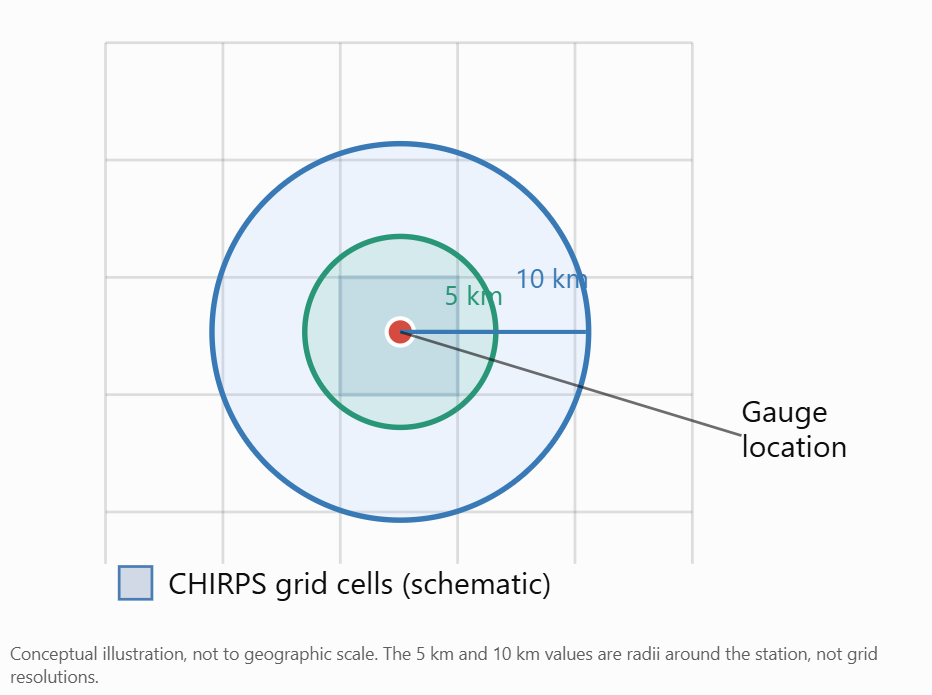

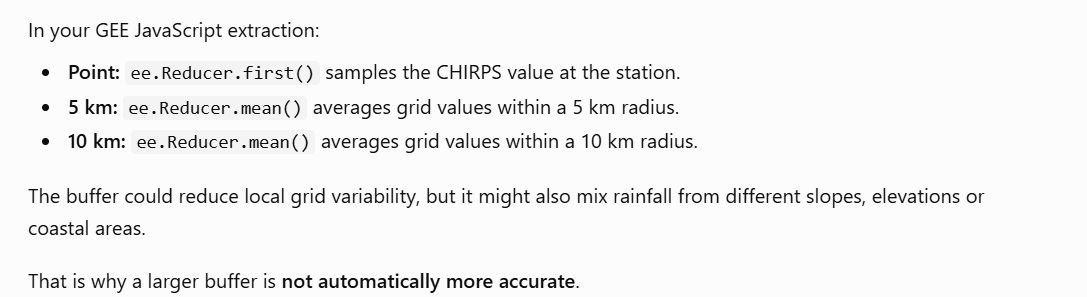

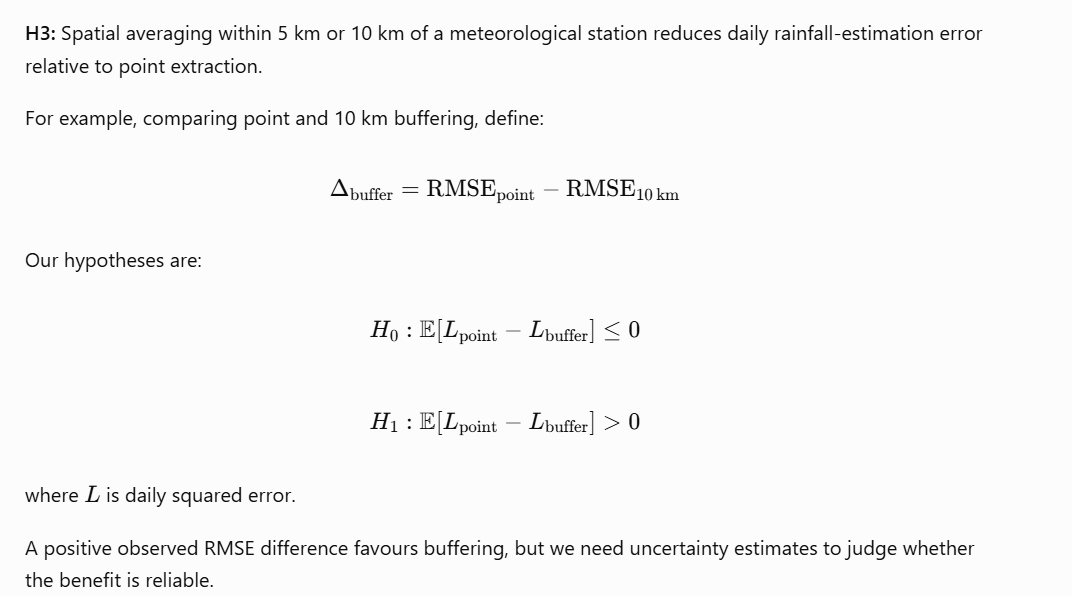

Because your current table contains 1981–2000, it is suitable for descriptive analysis, not for selecting an optimal buffer radius. We should select any radius using 1981–1994 only, then report 1995–2000 separately.

For now, add the following cell below your buffer-results table.

Use the name of your existing buffer statistics DataFrame in place of buffer_scores if yours is different.

In [73]:

# H3: Descriptive point-versus-buffer comparison
# Input table columns:
# Station, Version, Spatial_support, n, RMSE, Pearson_r

h3 = buffer_scores.copy()

point = (
    h3[h3["Spatial_support"] == "Point"]
    [["Station", "Version", "RMSE", "Pearson_r"]]
    .rename(columns={
        "RMSE": "Point_RMSE",
        "Pearson_r": "Point_r"
    })
)

h3_compare = h3.merge(
    point, on=["Station", "Version"], how="left",
    validate="many_to_one"
)

h3_compare["RMSE_reduction_mm_day"] = (
    h3_compare["Point_RMSE"] - h3_compare["RMSE"]
)

h3_compare["RMSE_improvement_percent"] = (
    100 * h3_compare["RMSE_reduction_mm_day"]
    / h3_compare["Point_RMSE"]
)

h3_compare["Pearson_change"] = (
    h3_compare["Pearson_r"] - h3_compare["Point_r"]
)

display(
    h3_compare[
        ["Station", "Version", "Spatial_support",
         "n", "RMSE", "RMSE_improvement_percent",
         "Pearson_r", "Pearson_change"]
    ].round(3)
)


,Station,Version,Spatial_support,n,RMSE,RMSE_improvement_percent,Pearson_r,Pearson_change
0,Badulla,v2,Point,7300,11.971,0.000,0.393,0.000
1,Badulla,v2,5 km,7300,12.059,-0.735,0.404,0.012
2,Badulla,v2,10 km,7300,12.136,-1.377,0.405,0.012
3,Badulla,v3rnl,Point,7300,11.002,0.000,0.456,0.000
4,Badulla,v3rnl,5 km,7300,11.042,-0.370,0.461,0.005
5,Badulla,v3rnl,10 km,7300,11.212,-1.909,0.467,0.011
6,Colombo,v2,Point,7279,15.791,0.000,0.398,0.000
7,Colombo,v2,5 km,7279,15.669,0.773,0.407,0.009
8,Colombo,v2,10 km,7279,15.689,0.651,0.408,0.010
9,Colombo,v3rnl,Point,7279,14.838,0.000,0.465,0.000


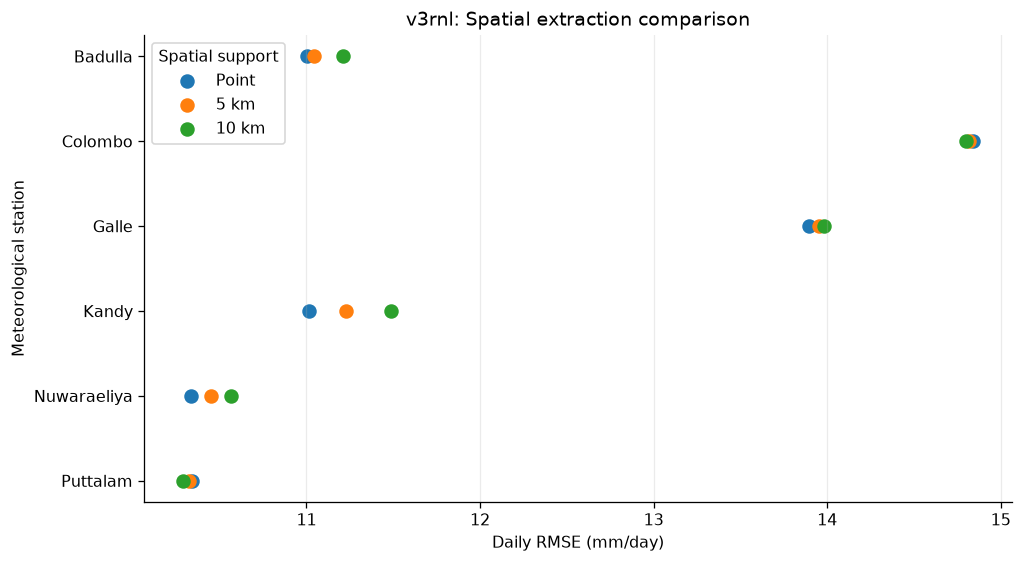

In [75]:
#H3 dot plot

def plot_h3_buffer_rmse(scores, version="v3rnl"):
    d = scores[scores["Version"] == version].copy()

    fig, ax = plt.subplots(figsize=(9, 5))

    order = ["Point", "5 km", "10 km"]
    stations = list(d["Station"].drop_duplicates())

    for support in order:
        subset = (
            d[d["Spatial_support"] == support]
            .set_index("Station")
            .reindex(stations)
        )
        ax.scatter(
            subset["RMSE"],
            range(len(stations)),
            label=support,
            s=65
        )

    ax.set_yticks(range(len(stations)))
    ax.set_yticklabels(stations)
    ax.invert_yaxis()
    ax.set_xlabel("Daily RMSE (mm/day)")
    ax.set_ylabel("Meteorological station")
    ax.set_title(
        f"{version}: Spatial extraction comparison"
    )
    ax.legend(title="Spatial support")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    return fig, ax


fig, ax = plot_h3_buffer_rmse(
    h3_compare, version="v3rnl"
)
plt.show()


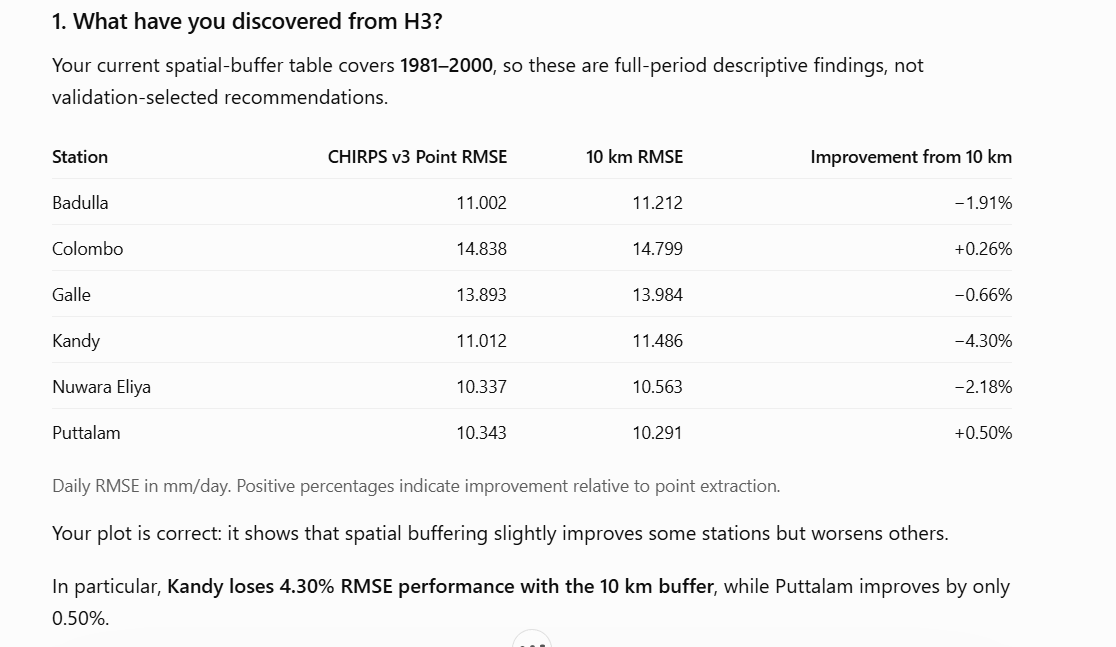

### H3 — Effect of Spatial Buffering

The effect of spatial averaging was investigated by comparing point-based CHIRPS estimates with mean precipitation extracted within 5 km and 10 km radii at six meteorological stations during 1981–2000.

For CHIRPS v3 RNL, increasing the buffer radius produced small improvements in Pearson correlation at all six stations. However, reductions in daily RMSE were observed only at Colombo and Puttalam using the 10 km buffer, with improvements of 0.26% and 0.50%, respectively. At Badulla, Galle, Kandy and Nuwara Eliya, point extraction produced lower RMSE than the spatial averages.

These findings indicate that spatial averaging does not consistently improve rainfall-estimation accuracy. The differences may arise from spatial variability in rainfall and the mismatch between point-gauge observations and surrounding gridded estimates, although these explanations have not been established causally.

**Conclusion:** The full-period descriptive results do not support a universal advantage for larger spatial buffers. The appropriate extraction support appears station-dependent, and any buffer selection requires chronological validation and uncertainty assessment.

Redo H3 using validation years only
Your original buffer comparison included 1981–2000. To decide whether buffering is beneficial without looking at the historical test period, we should calculate the same results for 1991–1994.
It uses the existing check DataFrame created by the buffer section.

In [81]:

# H3 — Spatial buffer comparison on validation dates only
# 1991–1994; no model is fitted here.

def score_buffers_by_period(buffer_data, period=VALID):
    start, end = pd.to_datetime(period)
    d = buffer_data.loc[
        buffer_data["Date"].between(start, end)
    ].copy()

    columns = [
        ("Point", "Point_mm"),
        ("5 km", "Buffer5km_mm"),
        ("10 km", "Buffer10km_mm")
    ]

    rows = []

    for station in STATIONS:
        s = d[d["Station"] == station]

        for version in ["v2", "v3rnl"]:
            # Require the same valid gauge dates for all three radii
            names = [c + "_" + version for _, c in columns]
            common = s.dropna(subset=["Rainfall_mm", *names])

            common = common[
                (common[["Rainfall_mm", *names]] >= 0).all(axis=1)
            ]

            for radius, col in columns:
                scores = paired_scores(
                    common["Rainfall_mm"],
                    common[col + "_" + version]
                )

                rows.append({
                    "Station": station,
                    "Version": version,
                    "Spatial_support": radius,
                    "n": scores["n"],
                    "RMSE": scores["RMSE"],
                    "Pearson_r": scores["Pearson_r"]
                })

    return pd.DataFrame(rows)


h3_validation = score_buffers_by_period(check, VALID)

display(h3_validation.round(3))


,Station,Version,Spatial_support,n,RMSE,Pearson_r
0,Badulla,v2,Point,1461,11.305,0.467
1,Badulla,v2,5 km,1461,11.432,0.476
2,Badulla,v2,10 km,1461,11.522,0.471
3,Badulla,v3rnl,Point,1461,10.820,0.413
4,Badulla,v3rnl,5 km,1461,10.916,0.422
5,Badulla,v3rnl,10 km,1461,11.109,0.430
6,Colombo,v2,Point,1460,18.541,0.429
7,Colombo,v2,5 km,1460,18.361,0.441
8,Colombo,v2,10 km,1460,18.338,0.444
9,Colombo,v3rnl,Point,1460,17.957,0.461


,Station,Version,Spatial_support,n,RMSE,Pearson_r,Point_RMSE,Improvement_percent
0,Badulla,v2,Point,1461,11.305,0.467,11.305,0.000
1,Badulla,v2,5 km,1461,11.432,0.476,11.305,-1.129
2,Badulla,v2,10 km,1461,11.522,0.471,11.305,-1.921
3,Badulla,v3rnl,Point,1461,10.820,0.413,10.820,0.000
4,Badulla,v3rnl,5 km,1461,10.916,0.422,10.820,-0.891
5,Badulla,v3rnl,10 km,1461,11.109,0.430,10.820,-2.668
6,Colombo,v2,Point,1460,18.541,0.429,18.541,0.000
7,Colombo,v2,5 km,1460,18.361,0.441,18.541,0.971
8,Colombo,v2,10 km,1460,18.338,0.444,18.541,1.094
9,Colombo,v3rnl,Point,1460,17.957,0.461,17.957,0.000


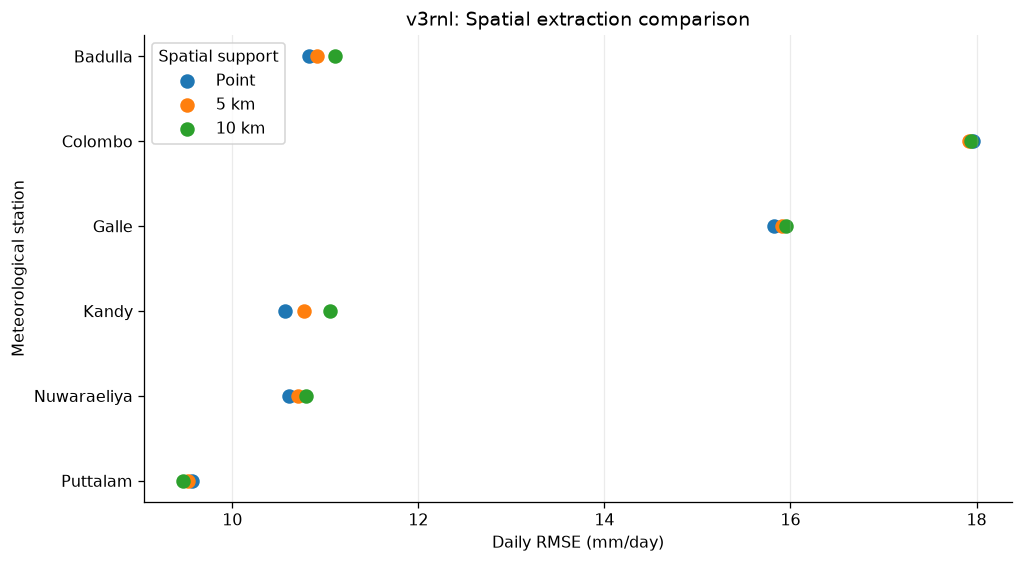

In [83]:
#Then rerun the improvement comparison using h3_validation instead of the earlier full-period buffer_scores.

# Point is the reference within each station and product

ref = (
    h3_validation[
        h3_validation["Spatial_support"] == "Point"
    ][["Station", "Version", "RMSE"]]
    .rename(columns={"RMSE": "Point_RMSE"})
)

h3_validation_comparison = h3_validation.merge(
    ref, on=["Station", "Version"],
    validate="many_to_one"
)

h3_validation_comparison["Improvement_percent"] = (
    100 * (
        h3_validation_comparison["Point_RMSE"]
        - h3_validation_comparison["RMSE"]
    ) / h3_validation_comparison["Point_RMSE"]
)

display(h3_validation_comparison.round(3))

fig, ax = plot_h3_buffer_rmse(
    h3_validation_comparison, version="v3rnl"
)
plt.show()


## 8. Interpretation worksheet and hypothesis conclusions
Complete this after examining the output CSVs and plots:

1. **H1:** For which stations does v3 have lower validation daily RMSE? Does Pearson always move in the same direction? Write the numbers and units.
2. **H2:** Which station's monthly correlation is highest? Report its **number of complete months** and monthly RMSE (mm/month), not just correlation.
3. **H4:** Is the daily within-pentad allocation fraction MAE lower for v3? Does that mean the v3 monthly total is necessarily more accurate? Why not?
4. **H3:** If buffers are unavailable, record *not evaluated*; do not infer improvement from point data. If available, compare strictly matched dates, and do not select a radius on the historical test years.
5. **Limitations:** CHIRPS and gauges differ in spatial support; observation day may not align perfectly; CHIRPS may assimilate gauges; different temporal scales have different units and sample counts.

**Next:** Notebook 03 will evaluate daily correction models with rolling-origin validation, maintaining raw v2 and raw v3 RNL as baselines. Notebook 04 will test direct pentad/monthly correction and the daily-sum alternative.


## 9. Scientific references and reproducibility
1. Funk, C. et al. (2015), *The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes*, **Scientific Data**, 2, 150066. https://doi.org/10.1038/sdata.2015.66
2. Funk, C. et al. (2026), *The Climate Hazards Center Infrared Precipitation with Stations, Version 3*, **Scientific Data**. https://doi.org/10.1038/s41597-026-07096-4
3. Google Earth Engine, CHIRPS v2 daily: https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY
4. Google Earth Engine, CHIRPS v3 RNL daily: https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL
5. User's existing extraction script: `scripts/11_CHIRPS_Buffered_Extraction_GEE_FIXED.js` (or archive copy).
6. PH3043 original rainfall project brief (provided by supervisor). The compulsory lab requirement is already addressed in Final Notebook 01. This notebook is the **v2/v3 and temporal/spatial research extension**.

**Important:** No external figure is represented as original. Every saved graph in this notebook is computed from this project's existing paired data. PNG and vector PDF are exported in a new `run_###` subfolder.


## Final Scientific Conclusions — Notebook 02

This notebook investigated four hypotheses concerning CHIRPS v2 and CHIRPS v3 RNL rainfall estimates at six Sri Lankan meteorological stations.

**H1 — Product accuracy:** CHIRPS v3 RNL achieved lower daily RMSE than CHIRPS v2 at all six stations during 1991–1994. Observed RMSE reductions ranged from 3.15% at Colombo to 21.03% at Nuwara Eliya. Exploratory year-block bootstrap intervals favoured v3 at four stations, although inference is limited by the four-year validation period.

**H2 — Temporal aggregation:** Both products showed higher Pearson correlation and lower mean-normalized RMSE at monthly resolution than at daily resolution. For CHIRPS v3 RNL, the mean station-wise Pearson correlation increased from 0.433 to 0.919, while mean-normalized RMSE decreased from 242.73% to 34.04%. These differences indicate improved representation of accumulated rainfall variability and lower relative errors at longer temporal scales. However, aggregation did not eliminate systematic bias, and the comparisons remain descriptive.

**H3 — Spatial buffering:** Spatial averaging within 5 km and 10 km radii did not consistently improve rainfall accuracy. In the 1991–1994 validation period, point extraction yielded the lowest CHIRPS v3 RNL daily RMSE at four stations, whereas the 5 km buffer performed best at Colombo and the 10 km buffer at Puttalam. These differences were generally small, and larger buffers were not universally beneficial.

**H4 — Within-pentad rainfall allocation:** On matched eligible pentads, CHIRPS v3 RNL achieved lower daily allocation-fraction MAE than v2 at all six stations, with relative reductions ranging from approximately 4.99% to 23.82%. This suggests improved within-pentad rainfall distribution, although it does not guarantee more accurate accumulated totals.

**Overall conclusion:** CHIRPS v3 RNL generally outperformed v2 in daily rainfall RMSE, monthly-scale agreement and within-pentad allocation during the validation period. However, product performance depended on the evaluation metric, station and spatial support. Higher correlation did not necessarily imply lower rainfall error, and spatial buffering showed mixed results.

These findings motivate the next stage of the research: developing separately validated daily and accumulated-rainfall calibration models while evaluating rainfall occurrence, heavy-rainfall errors and temporal generalization.

**Limitations:** The comparison involves six gauge locations, potentially different satellite-grid and observational-day definitions, and products that may incorporate gauge information. Some validation comparisons have limited independent temporal blocks. The 1995–2000 historical period was previously inspected during exploratory research and should not be described as a completely untouched test dataset.